<a href="https://colab.research.google.com/github/princewillodum/Game/blob/main/calabar_atm_site_selection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Install the packages. Nothing is pinned. If a new version breaks the notebook, restart the session and run again.
import subprocess, sys
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "numpy", "pandas", "geopandas", "shapely",
                       "rasterio", "scipy", "osmnx", "networkx", "matplotlib", "requests", "pillow", "pyogrio"])
print("Install step finished. If you see errors above, restart the session and run this cell again.")

Install step finished. If you see errors above, restart the session and run this cell again.


In [2]:
# ========================= SETTINGS =========================
# Change values here only. Names are in CAPITALS.

GRID_M = 100              # Size of each analysis cell in metres.
SERVICE_RADIUS_M = 500    # How far a customer will walk to an ATM, in metres.
MIN_SPACING_M = 150       # A new ATM must be at least this far from an existing ATM.
N_NEW_ATMS = 10           # How many new ATM sites to choose.
BUFFER_KM = 3             # Extra distance around the two LGAs, in kilometres.
OUT_DPI = 200             # Picture quality for saved maps. Higher is sharper and bigger.
CUSTOMER_CSV = None       # Path to an anonymised CSV, or None. Needs: latitude, longitude, weight.

# --- Study area ---
LGA_NAMES = ["Calabar Municipal", "Calabar South"]   # Names must match geoBoundaries ADM2.
START_BBOX = (8.25, 4.85, 8.45, 5.10)                # (west, south, east, north) in degrees. A starting box only.
CRS_METRIC = "EPSG:32632"                            # Metric CRS used for all distances and areas.
CRS_LATLON = "EPSG:4326"                             # Latitude and longitude, used for downloads.

# --- Flood rule (PLACEHOLDER: replace with a local, trusted rule) ---
LOW_ELEV_M = 5.0          # Candidates below this height (metres) are treated as flood-prone and dropped.

# --- Demand generator weights (how much demand each place type adds) ---
# These are assumptions. Higher number = stronger pull for ATM use. Edit them freely.
DEMAND_WEIGHTS = {
    "market": 1.0,
    "university": 0.9,
    "hospital": 0.7,
    "fuel_station": 0.8,
    "supermarket_mall": 0.9,
    "transport_hub": 0.8,
    "school": 0.4,
}
POP_SHARE = 0.5           # Share of the final demand that comes from population (0 to 1).
KDE_BANDWIDTH_M = 500     # Smoothing distance for the kernel density, in metres.

# --- AHP criteria and pairwise matrix ---
# Order of criteria matters. Row i vs column j: how much more important is i than j?
# Scale: 1 = equal, 3 = moderate, 5 = strong, 7 = very strong, 9 = extreme. 2, 4, 6, 8 sit in between.
# Values below the diagonal are filled in automatically as 1 divided by the upper value.
CRITERIA = ["demand_in_radius", "gap_served", "road_frontage", "activity_24h",
            "secure_host", "low_flood", "spacing"]
AHP_UPPER = {   # (row, col): value. Only the upper triangle is typed.
    (0,1):2, (0,2):2, (0,3):2, (0,4):3, (0,5):3, (0,6):6,
    (1,2):2, (1,3):2, (1,4):2, (1,5):2, (1,6):4,
    (2,3):1, (2,4):2, (2,5):2, (2,6):3,
    (3,4):2, (3,5):2, (3,6):3,
    (4,5):1, (4,6):2,
    (5,6):2,
}
AHP_MAX_CR = 0.10         # The notebook stops if the consistency ratio is at or above this.
WEIGHT_PERTURB = 0.20     # +/- 20 percent weight change used in the sensitivity step.

# --- Sensitivity values ---
SENS_RADII_M = [300, 500, 1000]
SENS_N = [5, 10, 15]

# --- Output ---
OUT_DIR = "atm_outputs"   # Folder for all results. It is deleted when the Colab session ends.

# --- Data links ---
# I am not sure these exact links are current. Check each official page and fix them if needed.
GEOBOUNDARIES_API = "https://www.geoboundaries.org/api/current/gbOpen/NGA/ADM2/"   # Check: https://www.geoboundaries.org
WORLDPOP_URL = "https://data.worldpop.org/GIS/Population/Global_2000_2020/2020/NGA/nga_ppp_2020.tif"  # Check: https://www.worldpop.org
WORLDCOVER_URL = "https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/ESA_WorldCover_10m_2021_v200_N03E006_Map.tif"  # Check: https://esa-worldcover.org
TERRAIN_URL = "https://s3.amazonaws.com/elevation-tiles-prod/terrarium/{z}/{x}/{y}.png"  # Check: https://registry.opendata.aws/terrain-tiles/
TERRAIN_ZOOM = 12         # Map tile zoom level. Higher = sharper but more tiles to download.
# If a download fails, download the file by hand and put its path here. None = use the web link.
LOCAL_FILES = {"population": None, "landcover": None, "elevation": None}

# --- Demand surface extras ---
NORM_PCT = 99             # Maps are scaled so this percentile of cells equals 1. Stops a few extreme cells washing out the map.
CUSTOMER_SHARE = 0.7      # Only used if CUSTOMER_CSV works: its share of the final demand (0 to 1). Proxies fill the rest.

# --- Distance settings ---
USE_NETWORK = True          # True = try walking distance on the road network. False = straight-line only.
MAX_NETWORK_NODES = 150000  # If the road graph has more nodes than this, use straight-line distance and warn.

# --- Candidate site settings ---
# Host place types that can become candidate sites. Order = priority when two hosts sit almost on top of each other.
CAND_HOST_LAYERS = ["fuel_stations", "banks", "supermarkets_malls", "markets", "hospitals", "universities"]
CAND_DEDUP_M = 25         # Hosts closer than this (metres) are treated as the same place. Only the first in the list is kept.

# --- Suitability settings ---
# Road class -> frontage score (0 to 1). Placeholder judgement: busier roads give more passing trade.
ROAD_CLASS_SCORES = {"motorway": 1.0, "trunk": 1.0, "primary": 1.0, "secondary": 0.8, "tertiary": 0.6,
                     "unclassified": 0.4, "residential": 0.4, "living_street": 0.3, "service": 0.3,
                     "pedestrian": 0.2, "footway": 0.1, "path": 0.1, "track": 0.1, "steps": 0.0}
ROAD_DEFAULT_SCORE = 0.2    # Score for a road class that is not in the table above.
FRONTAGE_SEARCH_M = 50      # A host counts as "on a road" only if a mapped road is this close (metres).
# 24-hour activity proxies. I do NOT check opening hours. These place types are only guessed to be busy at night.
ACTIVITY_WEIGHTS = {"fuel_stations": 1.0, "hospitals": 1.0, "transport_hubs": 0.7}
ACTIVITY_RADIUS_M = 300     # Count activity places within this distance of the candidate (metres).
ACTIVITY_CAP = 3.0          # A weighted count at or above this gets the full score of 1.
SECURE_NEAR_M = 100         # A bank or fuel station this close counts as a "secure host nearby" (metres).
SECURE_NEAR_SCORE = 0.7     # Score if a bank or fuel station is nearby but is not the host itself.
FLOOD_FULL_M = 10.0         # Flood score reaches 1 at LOW_ELEV_M + this many metres. Placeholder.
FLOOD_UNKNOWN_SCORE = 0.5   # Neutral score when the elevation is unknown. These sites are flagged.
SPACING_FULL_M = 500        # Spacing score reaches 1 when the nearest existing ATM is this far (metres).

# --- Greedy selection setting ---
MIN_SUITABILITY = 0.0     # Candidates scoring below this (0-100) cannot be picked. 0 = no floor. Placeholder.

# --- Scenario: no existing ATMs ---
# True = if no ATMs are found in OSM (and none are given in ATMS_CSV), carry on and ASSUME there are none.
# Then ALL demand counts as uncovered, "coverage before" is 0 by assumption, and the 'gap_served' and
# 'spacing' criteria are dropped. Every map and the brief say so. False = stop with an error instead.
ASSUME_NO_EXISTING_ATMS = True

# --- ATM download robustness ---
OSM_RETRIES = 3           # How many times to try each Overpass download before giving up.
OSM_TIMEOUT_S = 180       # Seconds to wait for Overpass on each try.
# Known ATM locations you collected yourself (optional). CSV columns: latitude, longitude. Optional: name.
ATMS_CSV = None           # Path to the CSV, or None.
ATMS_CSV_MODE = "add"     # "add" = join them to the OSM ATMs. "replace" = use only the CSV.

print("Settings read. radius =", SERVICE_RADIUS_M, "m | N =", N_NEW_ATMS)
# ============================================================

Settings read. radius = 500 m | N = 10


In [3]:
# Import the standard tools.
import os                      # For folders and file paths.
import sys                     # For Python system details.
import warnings                # For controlling warning messages.
import numpy as np             # Fast number arrays.
import pandas as pd            # Tables.
import geopandas as gpd        # Maps with tables (vector data).
import shapely                 # Geometry shapes (points, polygons).
import shapely.geometry        # Make sure the geometry sub-module is loaded.
from shapely.geometry import Point, box
import rasterio                # Raster (grid) files.
import scipy                   # Science tools (distances, smoothing).
import networkx as nx          # Road network graphs.
import osmnx as ox             # Downloads OSM data and builds road networks.
import matplotlib              # Plotting.
if "google.colab" not in sys.modules and not os.environ.get("DISPLAY") and not os.environ.get("MPLBACKEND"):
    matplotlib.use("Agg")      # Outside a notebook with no screen, draw to files only.
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)   # Hide noisy, harmless warnings.
os.makedirs(OUT_DIR, exist_ok=True)                         # Make the output folder if missing.

# ---------- Helper functions ----------
def say(msg):
    """Print a normal message with a tag, so it is easy to spot."""
    print("[INFO]", msg)

def warn(msg):
    """Print a loud warning. Use this for any failure so nothing is hidden."""
    print("[WARNING]", msg)

def get_ohsome_key():
    """Read OHSOME_API_KEY from Colab Secrets as text. Return None if not set.
    Never prints the key. Stops with a clear message if the key is not text."""
    try:
        from google.colab import userdata          # Only exists inside Colab.
        key = userdata.get("OHSOME_API_KEY")       # Ask Colab for the secret.
    except Exception:
        return None                                # Not in Colab, or no secret set.
    if isinstance(key, dict):                      # Some versions return a dictionary.
        for k in ("value", "key", "secret"):       # Try common field names.
            if k in key and isinstance(key[k], str):
                key = key[k]
                break
    if key is None:
        return None
    if not isinstance(key, str):                   # Still not text: stop clearly.
        raise TypeError("OHSOME_API_KEY was found but is not text. "
                        "Please re-save it as plain text in Colab Secrets.")
    return key.strip()

# ---------- Dataset availability table (filled in by later cells) ----------
LAYER_NAMES = ["lgas", "population", "landcover", "elevation", "atms", "banks", "markets",
               "schools", "universities", "hospitals", "fuel_stations", "supermarkets_malls",
               "transport_hubs", "roads", "customer_csv"]
AVAILABILITY = {name: False for name in LAYER_NAMES}     # Start with everything False.

# ---------- Data register: official pages to check ----------
DATA_REGISTER = pd.DataFrame([
    ("Boundaries (ADM2)",     "geoBoundaries",           "https://www.geoboundaries.org"),
    ("Population 2020, 100 m","WorldPop",                "https://www.worldpop.org"),
    ("Land cover 2021",       "ESA WorldCover",          "https://esa-worldcover.org"),
    ("Elevation",             "Terrain Tiles on AWS",    "https://registry.opendata.aws/terrain-tiles/"),
    ("Places and roads",      "OpenStreetMap / Overpass","https://wiki.openstreetmap.org/wiki/Overpass_API"),
    ("OSM downloader",        "OSMnx docs",              "https://osmnx.readthedocs.io"),
    ("Optional OSM API",      "ohsome",                  "https://docs.ohsome.org/"),
], columns=["Layer", "Source", "Official page to check"])

# ---------- Print what we have ----------
say(f"numpy {np.__version__} | pandas {pd.__version__} | geopandas {gpd.__version__}")
say(f"shapely {shapely.__version__} | rasterio {rasterio.__version__} | osmnx {ox.__version__}")
say(f"Output folder: {os.path.abspath(OUT_DIR)}")
say(f"Ohsome key found: {get_ohsome_key() is not None}")    # Prints True or False only, never the key.
print()
print(DATA_REGISTER.to_string(index=False))

[INFO] numpy 2.4.6 | pandas 2.2.3 | geopandas 1.2.0
[INFO] shapely 2.2.0 | rasterio 1.5.2 | osmnx 2.1.1
[INFO] Output folder: /content/atm_outputs
[INFO] Ohsome key found: True

                 Layer                   Source                           Official page to check
     Boundaries (ADM2)            geoBoundaries                    https://www.geoboundaries.org
Population 2020, 100 m                 WorldPop                         https://www.worldpop.org
       Land cover 2021           ESA WorldCover                       https://esa-worldcover.org
             Elevation     Terrain Tiles on AWS     https://registry.opendata.aws/terrain-tiles/
      Places and roads OpenStreetMap / Overpass https://wiki.openstreetmap.org/wiki/Overpass_API
        OSM downloader               OSMnx docs                     https://osmnx.readthedocs.io
      Optional OSM API                   ohsome                         https://docs.ohsome.org/


In [4]:
from rasterio.transform import from_origin, array_bounds   # Helpers for raster positions.
from scipy import ndimage                                   # Tools for smoothing.

def union_geoms(gdf):
    """Join all shapes in a GeoDataFrame into one shape. Works in old and new geopandas."""
    return gdf.geometry.union_all() if hasattr(gdf.geometry, "union_all") else gdf.geometry.unary_union

say("Helper functions defined.")

[INFO] Helper functions defined.


In [5]:
import requests                                             # For web calls (the boundary API).

# OSM tags for each layer. A list means "any of these values".
OSM_TAGS = {
    "atms": {"amenity": "atm", "atm": "yes"},   # Stand-alone ATMs, plus banks and shops tagged atm=yes.
    "banks": {"amenity": "bank"},
    "markets": {"amenity": "marketplace"},
    "schools": {"amenity": "school"},
    "universities": {"amenity": "university"},
    "hospitals": {"amenity": "hospital"},
    "fuel_stations": {"amenity": "fuel"},
    "supermarkets_malls": {"shop": ["supermarket", "mall"]},
    "transport_hubs": {"amenity": "bus_station", "public_transport": "station"},
}

ox.settings.use_cache = True                                # Save downloads so repeats are fast.
ox.settings.log_console = False                             # Keep OSMnx quiet.
ox.settings.requests_timeout = OSM_TIMEOUT_S                # Wait longer for busy Overpass servers.

def load_study_area():
    """Download Nigeria ADM2, keep our LGAs, build the buffered study area.
    Returns (lgas in metres, study area in metres, study polygon in lat/lon)."""
    say(f"Boundaries: geoBoundaries API at {GEOBOUNDARIES_API}")
    meta = requests.get(GEOBOUNDARIES_API, timeout=60).json()      # Ask the API where the file is.
    if isinstance(meta, list) and meta:                            # Some replies are a list.
        meta = meta[0]
    url = meta.get("gjDownloadURL") if isinstance(meta, dict) else None
    if not url:
        raise RuntimeError("geoBoundaries reply has no 'gjDownloadURL'. I am not sure of the current "
                           "field name. Check the API page at https://www.geoboundaries.org and fix "
                           "GEOBOUNDARIES_API or download the file by hand.")
    adm2 = gpd.read_file(url)                                      # Read all Nigeria LGAs.
    say(f"ADM2 features read: {len(adm2)}")
    if "shapeName" not in adm2.columns:
        raise RuntimeError(f"No 'shapeName' column. Columns found: {list(adm2.columns)}")
    lgas = adm2[adm2["shapeName"].isin(LGA_NAMES)].copy()          # Keep only our LGAs.
    if len(lgas) != len(LGA_NAMES):                                # Names did not match.
        near = adm2[adm2.intersects(box(*START_BBOX))]["shapeName"].tolist()
        raise ValueError(f"Found {len(lgas)} of {len(LGA_NAMES)} LGAs. Names inside your start box: "
                         f"{near}. Fix LGA_NAMES in the settings cell.")
    lgas = lgas.to_crs(CRS_LATLON)
    b = lgas.total_bounds                                          # West, south, east, north.
    say(f"Real LGA extent (deg): W {b[0]:.4f}, S {b[1]:.4f}, E {b[2]:.4f}, N {b[3]:.4f}")
    say(f"Start box (deg):       W {START_BBOX[0]}, S {START_BBOX[1]}, E {START_BBOX[2]}, N {START_BBOX[3]}")
    if b[0] < START_BBOX[0] or b[1] < START_BBOX[1] or b[2] > START_BBOX[2] or b[3] > START_BBOX[3]:
        warn("The real LGAs reach outside the start box. The real extent is used, not the box.")
    lgas_m = lgas.to_crs(CRS_METRIC)                               # Move to metres.
    study_m = gpd.GeoDataFrame({"name": ["study_area"]},
                               geometry=[union_geoms(lgas_m).buffer(BUFFER_KM * 1000)], crs=CRS_METRIC)
    study_ll = study_m.to_crs(CRS_LATLON).geometry.iloc[0]         # OSMnx needs lat/lon.
    say(f"LGA area: {union_geoms(lgas_m).area / 1e6:.1f} km2 | study area with buffer: "
        f"{study_m.geometry.iloc[0].area / 1e6:.1f} km2")
    return lgas_m, study_m, study_ll

def download_osm_layer(poly_ll, tags, label, study_m):
    """Download one OSM layer, retrying if Overpass is busy. Return points in metres, or None if it fails."""
    import time
    raw = None
    for attempt in range(1, OSM_RETRIES + 1):
        try:
            raw = ox.features_from_polygon(poly_ll, tags=tags)     # Ask Overpass through OSMnx.
            break
        except Exception as e:
            kind = type(e).__name__
            if kind == "InsufficientResponseError":                # Overpass answered: nothing matches. No retry.
                warn(f"OSM layer '{label}': Overpass found NO features with tags {tags} in the study area.")
                return None
            warn(f"OSM layer '{label}' try {attempt} of {OSM_RETRIES} failed: {kind}: {str(e)[:300]}")
            if attempt < OSM_RETRIES:
                time.sleep(10 * attempt)                           # Wait a little longer each time.
    if raw is None:
        warn(f"OSM layer '{label}' FAILED after {OSM_RETRIES} tries. See the messages above.")
        return None
    if len(raw) == 0:
        warn(f"OSM layer '{label}' returned no features.")
        return None
    raw = raw.to_crs(CRS_METRIC)                                   # Project first, then take centres.
    names = raw["name"] if "name" in raw.columns else pd.Series(None, index=raw.index, dtype=object)
    out = gpd.GeoDataFrame({"name": names.values, "source": "osm"},
                           geometry=raw.geometry.centroid.values, crs=CRS_METRIC)
    out = out[out.within(study_m.geometry.iloc[0])].reset_index(drop=True)   # Keep only inside the study area.
    say(f"OSM layer '{label}': {len(out)} features")
    return out

def load_atms_csv(path, study_m):
    """Read your own list of ATM locations (latitude, longitude, optional name). Returns metric points or None."""
    try:
        df = pd.read_csv(path)
        need = {"latitude", "longitude"}
        if not need.issubset(df.columns):
            raise ValueError(f"ATM CSV needs columns {sorted(need)}. Found {list(df.columns)}")
        df = df.dropna(subset=list(need))
        names = df["name"].astype(str) if "name" in df.columns else pd.Series("(ATM from CSV)", index=df.index)
        g = gpd.GeoDataFrame({"name": names.values, "source": "csv"},
                             geometry=gpd.points_from_xy(df["longitude"], df["latitude"]), crs=CRS_LATLON).to_crs(CRS_METRIC)
        g = g[g.within(study_m.geometry.iloc[0])].reset_index(drop=True)
        say(f"ATM CSV: {len(df)} rows read, {len(g)} inside the study area.")
        return g if len(g) > 0 else None
    except Exception as e:
        warn(f"ATM CSV failed: {type(e).__name__}: {str(e)[:200]}")
        return None

def load_roads(poly_ll):
    """Download the walking network and project it to metres. Returns (graph, edges) or (None, None)."""
    try:
        say("Downloading the walking road network. This can take a few minutes.")
        G = ox.graph_from_polygon(poly_ll, network_type="walk")    # Walkable streets and paths.
        G = ox.project_graph(G, to_crs=CRS_METRIC)                 # Metres, so lengths are in metres.
        edges = ox.graph_to_gdfs(G, nodes=False).reset_index(drop=True)
        # 'highway' can be a list. Keep the first value so it is one word.
        edges["highway"] = edges["highway"].apply(lambda v: v[0] if isinstance(v, list) else v)
        say(f"Road graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")
        return G, edges[["highway", "geometry"]]
    except Exception as e:
        warn(f"Road network failed: {type(e).__name__}: {str(e)[:120]}")
        return None, None

def load_customer_csv(path, study_m):
    """Read the optional customer CSV (latitude, longitude, weight). Returns metric points or None."""
    try:
        df = pd.read_csv(path)                                     # Read the file.
        need = {"latitude", "longitude", "weight"}
        if not need.issubset(df.columns):
            raise ValueError(f"CSV needs columns {sorted(need)}. Found {list(df.columns)}")
        n0 = len(df)
        df = df.dropna(subset=list(need))                          # Drop rows with blanks.
        df = df[df["weight"] > 0]                                  # Drop zero or negative weights.
        g = gpd.GeoDataFrame(df[["weight"]].copy(),
                             geometry=gpd.points_from_xy(df["longitude"], df["latitude"]), crs=CRS_LATLON)
        g = g.to_crs(CRS_METRIC)
        g = g[g.within(study_m.geometry.iloc[0])].reset_index(drop=True)   # Keep only inside the study area.
        say(f"Customer CSV: {n0} rows read, {len(g)} usable inside the study area.")
        warn("Customer data in use: use anonymised or aggregated data only. "
             "Follow the Nigeria Data Protection Act and your bank's policy.")
        return g if len(g) > 0 else None
    except Exception as e:
        warn(f"Customer CSV failed: {type(e).__name__}: {str(e)[:150]}")
        return None

say("Real-data functions for boundaries, OSM, roads and customers are defined.")

[INFO] Real-data functions for boundaries, OSM, roads and customers are defined.


In [6]:
from io import BytesIO                                      # To read image bytes in memory.
from rasterio.windows import from_bounds, Window, intersection
from rasterio.warp import transform_bounds

def read_raster_window(path_or_url, bounds_ll, label):
    """Read only the window of a raster that covers bounds_ll (west, south, east, north in degrees).
    Returns a dictionary with array, transform and crs."""
    say(f"Reading {label} from: {path_or_url}")
    with rasterio.open(path_or_url) as src:                          # Works for local files and web links.
        b = transform_bounds(CRS_LATLON, src.crs, *bounds_ll)        # Bounds in the raster's own CRS.
        w = from_bounds(*b, transform=src.transform)                 # Window in pixel units.
        w = Window(int(np.floor(w.col_off)), int(np.floor(w.row_off)),
                   int(np.ceil(w.width)) + 1, int(np.ceil(w.height)) + 1)   # Whole pixels, a little wider.
        w = intersection(w, Window(0, 0, src.width, src.height))     # Stay inside the file.
        arr = src.read(1, window=w).astype("float32")                # Read band 1.
        if src.nodata is not None:
            arr[arr == src.nodata] = np.nan                          # Mark no-data cells as NaN.
        out = {"array": arr, "transform": src.window_transform(w), "crs": str(src.crs)}
    say(f"{label}: array shape {arr.shape} (rows, cols), CRS {out['crs']}")
    return out

def _tile_xy(lon, lat, z):
    """Convert lon/lat to map tile numbers at zoom z (standard web map tiles)."""
    n = 2 ** z
    x = int((lon + 180.0) / 360.0 * n)
    y = int((1.0 - np.arcsinh(np.tan(np.radians(lat))) / np.pi) / 2.0 * n)
    return x, y

def load_terrarium(bounds_ll, zoom):
    """Download Terrarium tiles, stitch them, decode to metres. Returns a raster dictionary (EPSG:3857)."""
    from PIL import Image                                            # Reads PNG pictures.
    west, south, east, north = bounds_ll
    x0, y0 = _tile_xy(west, north, zoom)                             # Top-left tile.
    x1, y1 = _tile_xy(east, south, zoom)                             # Bottom-right tile.
    n_tiles = (x1 - x0 + 1) * (y1 - y0 + 1)
    say(f"Elevation: downloading {n_tiles} Terrarium tiles at zoom {zoom}")
    if n_tiles > 40:
        warn("More than 40 tiles. Consider a lower TERRAIN_ZOOM.")
    mosaic = np.zeros(((y1 - y0 + 1) * 256, (x1 - x0 + 1) * 256), dtype="float32")
    for tx in range(x0, x1 + 1):
        for ty in range(y0, y1 + 1):
            r = requests.get(TERRAIN_URL.format(z=zoom, x=tx, y=ty), timeout=60)
            r.raise_for_status()                                     # Stop on a bad reply.
            a = np.asarray(Image.open(BytesIO(r.content)).convert("RGB")).astype("float32")
            elev = a[:, :, 0] * 256.0 + a[:, :, 1] + a[:, :, 2] / 256.0 - 32768.0   # Terrarium formula.
            mosaic[(ty - y0) * 256:(ty - y0 + 1) * 256, (tx - x0) * 256:(tx - x0 + 1) * 256] = elev
    world = 2 * 20037508.342789244                                   # Width of the web map in metres.
    tile_m = world / (2 ** zoom)                                     # Width of one tile in metres.
    left = -20037508.342789244 + x0 * tile_m                         # Left edge of the mosaic.
    top = 20037508.342789244 - y0 * tile_m                           # Top edge of the mosaic.
    tr = from_origin(left, top, tile_m / 256, tile_m / 256)
    say(f"Elevation mosaic shape {mosaic.shape}; min {mosaic.min():.1f} m, max {mosaic.max():.1f} m")
    return {"array": mosaic, "transform": tr, "crs": "EPSG:3857"}

def _safe(fn, label):
    """Run fn(). If it fails, print a warning and return None, so one failure does not stop everything."""
    try:
        return fn()
    except Exception as e:
        warn(f"Layer '{label}' FAILED: {type(e).__name__}: {str(e)[:150]}")
        return None

def load_all_real():
    """Run every real loader. Returns one DATA dictionary with every layer."""
    for nm in ("GEOBOUNDARIES_API", "WORLDPOP_URL", "WORLDCOVER_URL", "TERRAIN_URL", "TERRAIN_ZOOM", "LOCAL_FILES"):
        if nm not in globals():
            raise NameError(f"Setting {nm} is missing. Run the settings cell first.")
    lgas, study, study_ll = load_study_area()                        # No LGAs = no analysis, so no _safe here.
    bounds_ll = study_ll.bounds                                      # West, south, east, north.
    data = {"lgas": lgas, "study": study}
    data["population"] = _safe(lambda: read_raster_window(LOCAL_FILES["population"] or WORLDPOP_URL, bounds_ll, "population"), "population")
    data["landcover"] = _safe(lambda: read_raster_window(LOCAL_FILES["landcover"] or WORLDCOVER_URL, bounds_ll, "landcover"), "landcover")
    if LOCAL_FILES["elevation"]:                                     # A local elevation file overrides the tiles.
        data["elevation"] = _safe(lambda: read_raster_window(LOCAL_FILES["elevation"], bounds_ll, "elevation"), "elevation")
    else:
        data["elevation"] = _safe(lambda: load_terrarium(bounds_ll, TERRAIN_ZOOM), "elevation")
    data["osm"] = {k: download_osm_layer(study_ll, tags, k, study) for k, tags in OSM_TAGS.items()}
    if ATMS_CSV:                                                     # Your own ATM list, if you gave one.
        extra = load_atms_csv(ATMS_CSV, study)
        base = data["osm"].get("atms")
        if extra is not None:
            if ATMS_CSV_MODE == "replace" or base is None:
                data["osm"]["atms"] = extra
            else:
                data["osm"]["atms"] = gpd.GeoDataFrame(pd.concat([base, extra], ignore_index=True), crs=CRS_METRIC)
            say(f"ATMs after adding the CSV: {len(data['osm']['atms'])} (mode: {ATMS_CSV_MODE}).")
    data["graph"], data["road_edges"] = load_roads(study_ll)
    data["customers"] = load_customer_csv(CUSTOMER_CSV, study) if CUSTOMER_CSV else None
    return data

say("Raster loaders and load_all_real() are defined.")

[INFO] Raster loaders and load_all_real() are defined.


[INFO] Boundaries: geoBoundaries API at https://www.geoboundaries.org/api/current/gbOpen/NGA/ADM2/
[INFO] ADM2 features read: 774
[INFO] Real LGA extent (deg): W 8.2224, S 4.8443, E 8.4015, N 5.0492
[INFO] Start box (deg):       W 8.25, S 4.85, E 8.45, N 5.1
[WARNING] The real LGAs reach outside the start box. The real extent is used, not the box.
[INFO] LGA area: 217.8 km2 | study area with buffer: 457.6 km2
[INFO] Reading population from: https://data.worldpop.org/GIS/Population/Global_2000_2020/2020/NGA/nga_ppp_2020.tif
[WARNING] Layer 'population' FAILED: RasterioIOError: Range downloading not supported by this server!
[INFO] Reading landcover from: https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/ESA_WorldCover_10m_2021_v200_N03E006_Map.tif
[INFO] landcover: array shape (3112, 2799) (rows, cols), CRS EPSG:4326
[INFO] Elevation: downloading 12 Terrarium tiles at zoom 12
[INFO] Elevation mosaic shape (1024, 768); min -582.0 m, max 381.0 m
[WARNING] OSM layer 'atms'

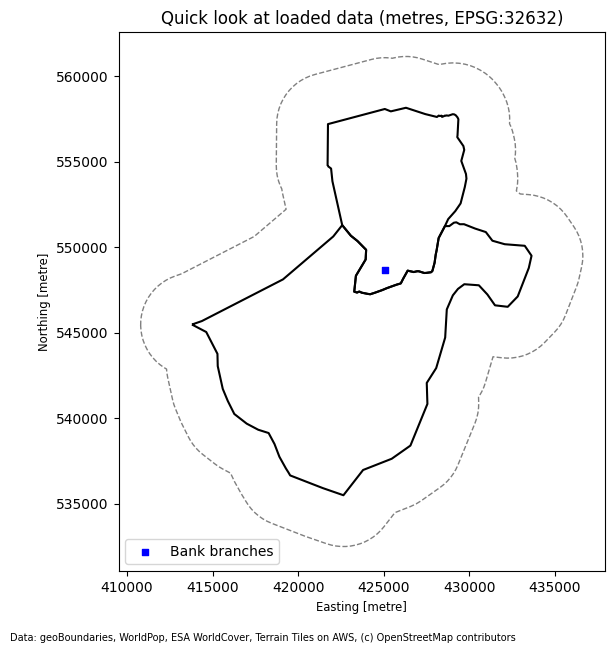

In [7]:
# ---- Load the real data ----
DATA = load_all_real()                                             # Download everything and build one dictionary.

# ---- Which layers are usable? ----
def _raster_ok(r):
    """True if the raster dictionary exists and has at least one valid (non-NaN) cell."""
    return r is not None and np.isfinite(r["array"]).any()

def _pts_ok(g):
    """True if the layer exists and has at least one feature."""
    return g is not None and len(g) > 0

AVAILABILITY.update({name: False for name in LAYER_NAMES})         # Reset everything to False.
AVAILABILITY["lgas"] = _pts_ok(DATA["lgas"])
AVAILABILITY["population"] = _raster_ok(DATA["population"])
AVAILABILITY["landcover"] = _raster_ok(DATA["landcover"])
AVAILABILITY["elevation"] = _raster_ok(DATA["elevation"])
for _k, _g in DATA["osm"].items():
    AVAILABILITY[_k] = _pts_ok(_g)
AVAILABILITY["roads"] = DATA["graph"] is not None and DATA["graph"].number_of_edges() > 0
AVAILABILITY["customer_csv"] = _pts_ok(DATA["customers"])

# ---- Dataset availability table ----
def _count(name):
    """Return a size note for the table (features or raster shape)."""
    if name == "lgas": return f"{len(DATA['lgas'])} LGAs"
    if name in ("population", "landcover", "elevation"):
        return f"{DATA[name]['array'].shape}" if DATA[name] else "-"
    if name == "roads": return f"{DATA['graph'].number_of_edges()} edges" if AVAILABILITY["roads"] else "-"
    if name == "customer_csv": return f"{len(DATA['customers'])} points" if AVAILABILITY[name] else "-"
    return f"{len(DATA['osm'][name])} features" if AVAILABILITY[name] else "-"

avail = pd.DataFrame({"layer": LAYER_NAMES,
                      "available": [AVAILABILITY[n] for n in LAYER_NAMES],
                      "size": [_count(n) for n in LAYER_NAMES],
                      "origin": ["real download" for _ in LAYER_NAMES]})
print("\nDATASET AVAILABILITY")
print(avail.to_string(index=False))

# ---- Criteria that must be dropped when their layers are missing ----
CRITERIA_NEEDS = {                      # A criterion is kept if ANY listed layer is available.
    "demand_in_radius": ["population", "customer_csv", "markets", "universities", "hospitals",
                         "fuel_stations", "supermarkets_malls", "transport_hubs", "schools"],
    "gap_served": ["atms"],
    "road_frontage": ["roads"],
    "activity_24h": ["fuel_stations", "hospitals", "transport_hubs"],
    "secure_host": ["banks", "fuel_stations"],
    "low_flood": ["elevation"],
    "spacing": ["atms"],
}
DROPPED_CRITERIA = [c for c in CRITERIA if not any(AVAILABILITY[l] for l in CRITERIA_NEEDS[c])]
if DROPPED_CRITERIA:
    warn(f"These criteria are DROPPED because their data are missing: {DROPPED_CRITERIA}. "
         f"The AHP step will re-calculate the weights openly and re-check the consistency ratio.")
else:
    say("All criteria have data. None dropped.")
missing = [n for n in LAYER_NAMES if not AVAILABILITY[n] and n != "customer_csv"]
if missing:
    warn(f"Layers that are False: {missing}")
if AVAILABILITY["roads"] is False:
    warn("No road network. Distance will use straight-line. Road frontage will be dropped.")

# ---- Hard stops ----
host_layers = ["fuel_stations", "banks", "markets", "supermarkets_malls", "hospitals", "universities"]
if not AVAILABILITY["lgas"]:
    raise RuntimeError("Stopping: no LGA boundaries.")
NO_ATM_ASSUMED = (not AVAILABILITY["atms"]) and ASSUME_NO_EXISTING_ATMS   # True = we carry on with zero ATMs.
NO_ATM_DIST_M = 1_000_000.0                                 # Stand-in distance (m) to the "nearest ATM" when there are none.
if not AVAILABILITY["atms"] and not ASSUME_NO_EXISTING_ATMS:
    _counts = {k: (0 if g is None else len(g)) for k, g in DATA["osm"].items()}
    raise RuntimeError(f"Stopping: no existing ATMs found. Features per OSM layer: {_counts}. "
                       "Scroll up for the [WARNING] line about 'atms'. If ALL layers are 0, Overpass probably failed or "
                       "was busy: wait a few minutes and run this cell again. If only 'atms' is 0, OSM has no ATMs mapped "
                       "here: set ATMS_CSV in the settings cell to a CSV of known ATM locations (latitude, longitude) "
                       "and re-run from the data-loading cell. Do not assume there are none.")
if NO_ATM_ASSUMED:
    DATA["osm"]["atms"] = gpd.GeoDataFrame({"name": pd.Series(dtype=object), "source": pd.Series(dtype=object)},
                                           geometry=gpd.GeoSeries([], crs=CRS_METRIC), crs=CRS_METRIC)   # Empty ATM layer.
    warn("NO EXISTING ATMs FOUND. ASSUME_NO_EXISTING_ATMS is True, so the analysis ASSUMES THERE ARE NONE. "
         "All demand counts as uncovered. The 'gap_served' and 'spacing' criteria will be dropped. "
         "Real ATMs may exist that OSM does not show: check each site on the ground.")
ATM_LABEL = "Existing ATMs: none assumed" if NO_ATM_ASSUMED else "Existing ATMs (OSM)"   # Legend text on maps.
if not any(AVAILABILITY[n] for n in CRITERIA_NEEDS["demand_in_radius"]):
    raise RuntimeError("Stopping: no demand source (no population, customers or demand places).")
if not any(AVAILABILITY[n] for n in host_layers):
    raise RuntimeError("Stopping: no host places (fuel stations, banks, markets, malls, hospitals, universities).")

# ---- Self-tests ----
vector_layers = [DATA["lgas"], DATA["study"]] + [g for g in DATA["osm"].values() if _pts_ok(g)]
assert all(g.crs.to_epsg() == 32632 for g in vector_layers), "A vector layer is not in EPSG:32632."
assert DATA["study"].geometry.iloc[0].area > 0, "Study area has no area."
for _n in ("population", "landcover", "elevation"):
    if DATA[_n] is not None:
        assert DATA[_n]["array"].ndim == 2, f"{_n} is not a 2D grid."
if AVAILABILITY["population"]:
    assert np.nanmin(DATA["population"]["array"]) >= 0, "Negative population found."
say("Self-tests passed: layers are metric, study area is positive, rasters are 2D.")

# ---- Printed summary with units ----
st = DATA["study"].geometry.iloc[0]
say(f"Study area: {st.area / 1e6:.1f} km2 | bounds (m, EPSG:32632): "
    f"{tuple(round(v) for v in st.bounds)}")
if AVAILABILITY["population"]:
    say(f"Total population in the raster window: {np.nansum(DATA['population']['array']):,.0f} people "
        f"(window may be bigger than the study area; the grid step clips it)")

# ---- Credits text for later maps ----
CREDITS = "Data: geoBoundaries, WorldPop, ESA WorldCover, Terrain Tiles on AWS, (c) OpenStreetMap contributors"

# ---- Quick-look map ----
fig, ax = plt.subplots(figsize=(7, 7))
DATA["lgas"].boundary.plot(ax=ax, color="black", linewidth=1.5)     # LGA outlines.
DATA["study"].boundary.plot(ax=ax, color="grey", linewidth=1, linestyle="--")
if AVAILABILITY["atms"]:
    DATA["osm"]["atms"].plot(ax=ax, color="red", marker="^", markersize=25, label="Existing ATMs")
if AVAILABILITY["banks"]:
    DATA["osm"]["banks"].plot(ax=ax, color="blue", marker="s", markersize=25, label="Bank branches")
ax.set_title("Quick look at loaded data (metres, EPSG:32632)")
ax.legend(loc="lower left")
fig.text(0.01, 0.01, CREDITS, fontsize=7)                           # Credits in the footer.
plt.show()

In [8]:
from rasterio.features import rasterize                     # Turns shapes into cell masks.
from rasterio.warp import reproject, Resampling             # Moves a raster onto another grid.
from rasterio.crs import CRS                                # Understands CRS names.

def build_grid(study_m, cell_m):
    """Make the one analysis grid. Edges snap to multiples of cell_m (metres)."""
    minx, miny, maxx, maxy = study_m.total_bounds           # Study area bounds in metres.
    left = np.floor(minx / cell_m) * cell_m                 # Snap each edge outwards.
    right = np.ceil(maxx / cell_m) * cell_m
    bottom = np.floor(miny / cell_m) * cell_m
    top = np.ceil(maxy / cell_m) * cell_m
    ncols = int(round((right - left) / cell_m))             # Number of columns.
    nrows = int(round((top - bottom) / cell_m))             # Number of rows.
    return {"transform": from_origin(left, top, cell_m, cell_m),   # Grid position and cell size.
            "shape": (nrows, ncols), "cell_m": cell_m,
            "left": left, "right": right, "bottom": bottom, "top": top,
            "xs": left + (np.arange(ncols) + 0.5) * cell_m,         # Cell-centre x values.
            "ys": top - (np.arange(nrows) + 0.5) * cell_m}          # Cell-centre y values (top to bottom).

def polygon_mask(geoms, grid):
    """Return True for cells whose centre is inside the given shapes."""
    m = rasterize([(g, 1) for g in geoms], out_shape=grid["shape"],
                  transform=grid["transform"], fill=0, all_touched=False, dtype="uint8")
    return m.astype(bool)                                   # Turn 0/1 into False/True.

def source_cell_area_m2(r):
    """Approximate area of one source cell in square metres."""
    t = r["transform"]                                      # Cell size lives in the transform.
    if CRS.from_user_input(r["crs"]).is_geographic:         # Degrees: convert to metres (approximate).
        lat = t.f + t.e * r["array"].shape[0] / 2           # Latitude near the window centre.
        dy = abs(t.e) * 110574.0                            # Metres per degree of latitude (approx).
        dx = abs(t.a) * 111320.0 * np.cos(np.radians(lat)) # Metres per degree of longitude (approx).
        return dx * dy
    return abs(t.a * t.e)                                   # Already metres.

def to_grid(r, grid, how="average"):
    """Resample a raster dictionary onto the analysis grid. NaN means no data."""
    dst = np.full(grid["shape"], np.nan, dtype="float32")   # Empty output grid.
    reproject(source=r["array"].astype("float32"), destination=dst,
              src_transform=r["transform"], src_crs=r["crs"],
              dst_transform=grid["transform"], dst_crs=CRS_METRIC,
              resampling=getattr(Resampling, how), src_nodata=np.nan, dst_nodata=np.nan)
    return dst

def population_to_grid(r, grid):
    """Resample population (people per cell) and keep the total about right."""
    density = (r["array"] / source_cell_area_m2(r)).astype("float32")   # People per square metre.
    d = to_grid({**r, "array": density}, grid, "average")               # Average the density.
    return d * grid["cell_m"] ** 2                                      # Back to people per 100 m cell.

def fraction_to_grid(r, code, grid):
    """Share (0 to 1) of each grid cell covered by one land-cover class."""
    a = r["array"]
    b = np.where(np.isnan(a), np.nan, (a == code).astype("float32")).astype("float32")  # 1 if class matches.
    return to_grid({**r, "array": b}, grid, "average")      # Average of 0/1 = share.

def snap_points(gdf, grid):
    """Add row, col and cell-centre x, y to each point. Drop points outside the grid."""
    if gdf is None or len(gdf) == 0:
        return gdf                                          # Nothing to snap.
    x, y = gdf.geometry.x.values, gdf.geometry.y.values     # Point coordinates in metres.
    col = np.floor((x - grid["left"]) / grid["cell_m"]).astype(int)   # Column number.
    row = np.floor((grid["top"] - y) / grid["cell_m"]).astype(int)    # Row number (counted from the top).
    ok = (row >= 0) & (row < grid["shape"][0]) & (col >= 0) & (col < grid["shape"][1])
    out = gdf[ok].copy().reset_index(drop=True)             # Keep points that fall on the grid.
    out["row"], out["col"] = row[ok], col[ok]
    out["cx"], out["cy"] = grid["xs"][col[ok]], grid["ys"][row[ok]]
    return out

def prepare_grid_layers(data):
    """Do all of the grid preparation. Returns (grid, layers). layers holds arrays on the grid."""
    grid = build_grid(data["study"], GRID_M)                # One grid for everything.
    shp = grid["shape"]
    L = {"in_study": polygon_mask(list(data["study"].geometry), grid),   # Inside study area.
         "in_lga": polygon_mask(list(data["lgas"].geometry), grid)}      # Inside the two LGAs.
    if AVAILABILITY["population"]:
        pop = population_to_grid(data["population"], grid)
        say(f"Population: {int(np.isnan(pop[L['in_study']]).sum())} study cells had no data (set to 0).")
        L["pop_total_before_mask"] = float(np.nansum(pop))  # Total before we cut to the study area.
        pop = np.clip(np.nan_to_num(pop, nan=0.0), 0, None) # No NaN, no negatives.
        pop[~L["in_study"]] = 0                             # No people outside the study area.
    else:
        warn("Population layer missing: using zeros.")
        pop, L["pop_total_before_mask"] = np.zeros(shp, "float32"), 0.0
    L["pop"] = pop.astype("float32")
    if AVAILABILITY["landcover"]:
        L["built"] = np.nan_to_num(fraction_to_grid(data["landcover"], 50, grid), nan=0.0)   # Built-up share.
        L["water_frac"] = np.nan_to_num(fraction_to_grid(data["landcover"], 80, grid), nan=0.0)  # Water share.
    else:
        warn("Land cover missing: no water mask and no built-up share. Water filter will be skipped.")
        L["built"], L["water_frac"] = np.zeros(shp, "float32"), np.zeros(shp, "float32")
    L["water"] = L["water_frac"] >= 0.5                     # A cell is water if half or more is water.
    if AVAILABILITY["elevation"]:
        L["elev"] = to_grid(data["elevation"], grid, "average")   # Metres above sea level.
    else:
        warn("Elevation missing: flood rule will be skipped and 'low_flood' will be dropped.")
        L["elev"] = np.full(shp, np.nan, dtype="float32")
    return grid, L

def snap_all(data, grid):
    """Snap every point layer to the grid. Print counts before and after."""
    for k, g in data["osm"].items():
        n0 = 0 if g is None else len(g)
        data["osm"][k] = snap_points(g, grid)
        n1 = 0 if data["osm"][k] is None else len(data["osm"][k])
        if n0 != n1:
            warn(f"Layer '{k}': {n0 - n1} points fell outside the grid and were dropped.")
    if data["customers"] is not None:
        data["customers"] = snap_points(data["customers"], grid)

# ---- Run it ----
GRID, LAYERS = prepare_grid_layers(DATA)
snap_all(DATA, GRID)

# ---- Print shapes, counts and units ----
nrows, ncols = GRID["shape"]
say(f"Grid: {nrows} rows x {ncols} cols = {nrows * ncols:,} cells of {GRID_M} m x {GRID_M} m "
    f"({GRID_M ** 2 / 10000:.1f} ha each)")
say(f"Cells inside study area: {LAYERS['in_study'].sum():,} "
    f"({LAYERS['in_study'].sum() * GRID_M ** 2 / 1e6:.1f} km2) | inside the LGAs: {LAYERS['in_lga'].sum():,} "
    f"({LAYERS['in_lga'].sum() * GRID_M ** 2 / 1e6:.1f} km2)")
say(f"Population on grid (study area): {LAYERS['pop'].sum():,.0f} people | "
    f"inside the LGAs: {LAYERS['pop'][LAYERS['in_lga']].sum():,.0f} people")
say(f"Water cells (study area): {(LAYERS['water'] & LAYERS['in_study']).sum():,} | "
    f"mean built-up share: {LAYERS['built'][LAYERS['in_study']].mean():.2f}")
if AVAILABILITY["elevation"]:
    e = LAYERS["elev"][LAYERS["in_study"]]
    say(f"Elevation (study area): min {np.nanmin(e):.1f} m, median {np.nanmedian(e):.1f} m, max {np.nanmax(e):.1f} m")
say("Points on grid: " + ", ".join(f"{k}={0 if g is None else len(g)}" for k, g in DATA["osm"].items()))

# ---- Self-tests ----
assert CRS.from_user_input(CRS_METRIC).to_epsg() == 32632, "CRS is not EPSG:32632."
assert abs(GRID["transform"].a) == GRID_M and abs(GRID["transform"].e) == GRID_M, "Cell size is not GRID_M."
assert GRID["left"] % GRID_M == 0 and GRID["top"] % GRID_M == 0, "Grid edges are not snapped to GRID_M."
for _k in ("in_study", "in_lga", "pop", "built", "water", "elev"):
    assert LAYERS[_k].shape == GRID["shape"], f"Layer shape does not match the grid: {_k}"
assert LAYERS["in_study"].sum() > 0 and LAYERS["in_lga"].sum() > 0, "A mask is empty."
assert GRID_M * GRID_M > 0 and DATA["study"].geometry.iloc[0].area > 0, "Negative or zero area."
assert (LAYERS["pop"] >= 0).all(), "Negative population on the grid."
say("Self-tests passed: metric CRS, snapped grid, matching shapes, no negative areas or people.")

[WARNING] Population layer missing: using zeros.
[INFO] Grid: 288 rows x 260 cols = 74,880 cells of 100 m x 100 m (1.0 ha each)
[INFO] Cells inside study area: 45,768 (457.7 km2) | inside the LGAs: 21,776 (217.8 km2)
[INFO] Population on grid (study area): 0 people | inside the LGAs: 0 people
[INFO] Water cells (study area): 8,160 | mean built-up share: 0.13
[INFO] Elevation (study area): min -73.1 m, median 12.6 m, max 92.7 m
[INFO] Points on grid: atms=0, banks=1, markets=3, schools=5, universities=2, hospitals=4, fuel_stations=3, supermarkets_malls=2, transport_hubs=5
[INFO] Self-tests passed: metric CRS, snapped grid, matching shapes, no negative areas or people.


In [9]:
# ---- Check the settings exist and make sense ----
for _nm in ("NORM_PCT", "CUSTOMER_SHARE"):
    if _nm not in globals():
        raise NameError(f"Setting {_nm} is missing. Run the settings cell first.")
assert 0 <= POP_SHARE <= 1 and 0 <= CUSTOMER_SHARE <= 1, "POP_SHARE and CUSTOMER_SHARE must be between 0 and 1."

# ---- Link each weight name to its layer name ----
GEN_LAYER = {"market": "markets", "university": "universities", "hospital": "hospitals",
             "fuel_station": "fuel_stations", "supermarket_mall": "supermarkets_malls",
             "transport_hub": "transport_hubs", "school": "schools"}
_bad = [k for k in DEMAND_WEIGHTS if k not in GEN_LAYER]
if _bad:
    raise ValueError(f"Unknown names in DEMAND_WEIGHTS: {_bad}. Allowed: {list(GEN_LAYER)}")

def bin_points(gdf, grid, weights=None):
    """Add points (or their weights) into grid cells. Returns a 2D array."""
    arr = np.zeros(grid["shape"], dtype="float64")          # Start with zero in every cell.
    if gdf is None or len(gdf) == 0:
        return arr                                          # No points, nothing to add.
    w = np.ones(len(gdf)) if weights is None else np.asarray(weights, dtype=float)   # One per point.
    np.add.at(arr, (gdf["row"].values, gdf["col"].values), w)   # Safe add, even for repeated cells.
    return arr

def smooth(arr, bandwidth_m, cell_m):
    """Gaussian kernel smoothing. bandwidth_m is the kernel standard deviation in metres."""
    return ndimage.gaussian_filter(arr, sigma=bandwidth_m / cell_m, mode="constant")   # sigma is in cells.

def norm01(a, mask, pct):
    """Scale to 0-1. The pct-th percentile inside mask becomes 1. Larger values are clipped."""
    vals = a[mask]                                          # Only look at valid cells.
    top = np.percentile(vals, pct) if vals.size else 0.0    # The value that maps to 1.
    if not np.isfinite(top) or top <= 0:                    # Too many zeros: use the maximum instead.
        top = vals.max() if vals.size else 0.0
    if top <= 0:
        return np.zeros(a.shape, dtype="float64")           # Layer is empty.
    out = np.clip(a / top, 0, 1)                            # Scale and clip.
    out[~mask] = 0                                          # Zero outside valid cells.
    return out

def build_demand(data, grid, layers):
    """Build the demand surface. Returns a dictionary with the surface, parts, shares and a table."""
    cell = grid["cell_m"]
    valid = layers["in_study"] & ~layers["water"]           # Cells where demand is allowed.
    parts, rows = {}, []                                    # Parts = scaled layers. Rows = table lines.
    # --- Part 1: demand places, weighted and smoothed ---
    places = np.zeros(grid["shape"])
    for key, w in DEMAND_WEIGHTS.items():
        layer = GEN_LAYER[key]
        g = data["osm"].get(layer)
        if (not AVAILABILITY[layer]) or g is None or len(g) == 0 or w <= 0:
            rows.append((key, layer, 0, w, "skipped"))      # Show skipped layers openly.
            continue
        places += w * smooth(bin_points(g, grid), KDE_BANDWIDTH_M, cell)   # Weight x smoothed count.
        rows.append((key, layer, len(g), w, "used"))
    if any(r[4] == "used" for r in rows):
        parts["places"] = norm01(places, valid, NORM_PCT)   # Scale the places layer to 0-1.
    # --- Part 2: population ---
    if AVAILABILITY["population"]:
        parts["population"] = norm01(layers["pop"].astype("float64"), valid, NORM_PCT)
    # --- Part 3: customers (optional, main layer when present) ---
    if data["customers"] is not None and len(data["customers"]) > 0:
        c = smooth(bin_points(data["customers"], grid, data["customers"]["weight"].values), KDE_BANDWIDTH_M, cell)
        parts["customers"] = norm01(c, valid, NORM_PCT)
    # --- Shares: re-calculated openly if a layer is missing ---
    if "places" in parts and "population" in parts:
        proxy = {"population": POP_SHARE, "places": 1 - POP_SHARE}
    elif "population" in parts:
        proxy = {"population": 1.0}
        warn("No demand places available: demand comes from POPULATION ONLY (share re-calculated to 1.0).")
    elif "places" in parts:
        proxy = {"places": 1.0}
        warn("No population available: demand comes from DEMAND PLACES ONLY (share re-calculated to 1.0).")
    else:
        proxy = {}
    if "customers" in parts:
        shares = {"customers": CUSTOMER_SHARE if proxy else 1.0}
        shares.update({k: v * (1 - CUSTOMER_SHARE) for k, v in proxy.items()})
        note = "Main demand layer: customer CSV (anonymised). Proxies fill the rest."
    else:
        shares = proxy
        note = "Demand inferred from proxies (OSM places + WorldPop population), not customer data."
    if not shares:
        raise RuntimeError("Stopping: demand is all zero. No demand layer worked.")
    demand = sum(s * parts[k] for k, s in shares.items())   # Weighted blend of the scaled layers.
    demand = np.where(valid, demand, 0.0)                   # Zero in water and outside the study area.
    if demand.max() <= 0:
        raise RuntimeError("Stopping: demand is all zero. Check the layers and settings.")
    demand = demand / demand.max()                          # Peak value is exactly 1.
    table = pd.DataFrame(rows, columns=["weight_name", "layer", "n_features", "weight", "status"])
    return {"demand": demand, "parts": parts, "shares": shares, "valid": valid, "table": table, "note": note}

# ---- Run it ----
DEM = build_demand(DATA, GRID, LAYERS)
DEMAND = DEM["demand"]                                      # The 0-1 demand surface, one value per cell.
DEMAND_NOTE = DEM["note"]                                   # Text to print on every map.
if NO_ATM_ASSUMED:
    DEMAND_NOTE += " | ASSUMPTION: no existing ATMs (none found in OSM)"

# ---- Print what happened ----
print("\nDEMAND PLACES")
print(DEM["table"].to_string(index=False))
say("Final shares of the demand surface: " + ", ".join(f"{k} = {v:.2f}" for k, v in DEM["shares"].items()))
say(DEMAND_NOTE)
d_study, d_lga = DEMAND[LAYERS["in_study"]], DEMAND[LAYERS["in_lga"]]
say(f"Demand index (0-1): mean {d_study.mean():.3f}, max {DEMAND.max():.2f}; "
    f"cells above 0.5: {(DEMAND > 0.5).sum():,}")
say(f"Total demand index (sum over cells, relative units): study area {d_study.sum():,.1f} | LGAs {d_lga.sum():,.1f}")
_r, _c = np.unravel_index(np.argmax(DEMAND), DEMAND.shape)  # Cell with the highest demand.
say(f"Highest-demand cell centre: x {GRID['xs'][_c]:.0f} m, y {GRID['ys'][_r]:.0f} m (EPSG:32632)")

[WARNING] No population available: demand comes from DEMAND PLACES ONLY (share re-calculated to 1.0).

DEMAND PLACES
     weight_name              layer  n_features  weight status
          market            markets           3     1.0   used
      university       universities           2     0.9   used
        hospital          hospitals           4     0.7   used
    fuel_station      fuel_stations           3     0.8   used
supermarket_mall supermarkets_malls           2     0.9   used
   transport_hub     transport_hubs           5     0.8   used
          school            schools           5     0.4   used
[INFO] Final shares of the demand surface: places = 1.00
[INFO] Demand inferred from proxies (OSM places + WorldPop population), not customer data. | ASSUMPTION: no existing ATMs (none found in OSM)
[INFO] Demand index (0-1): mean 0.039, max 1.00; cells above 0.5: 1,383
[INFO] Total demand index (sum over cells, relative units): study area 1,768.0 | LGAs 1,568.4
[INFO] Highest

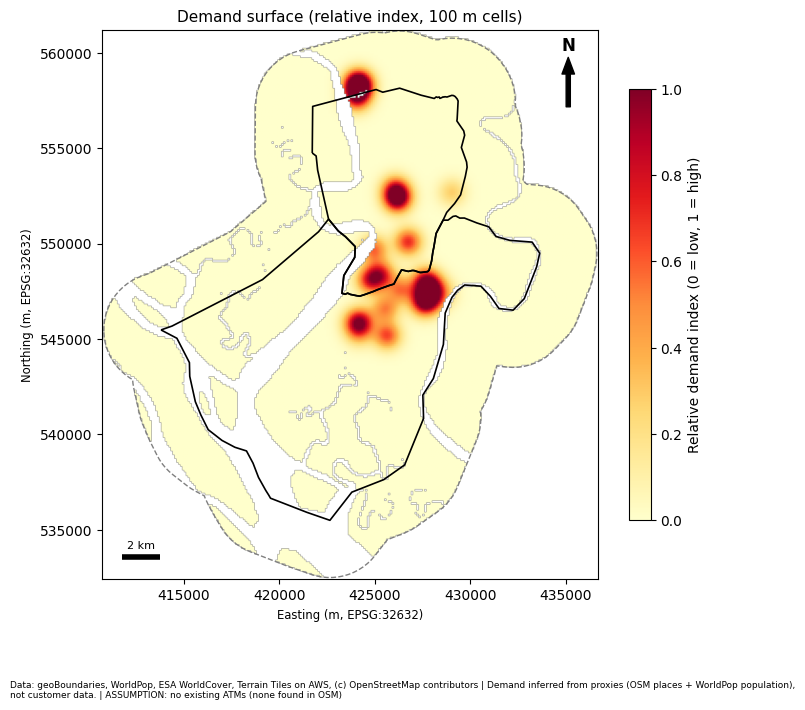

[INFO] Saved: atm_outputs/map_demand_surface.png
[INFO] Self-tests passed: demand is 0-1, zero in water and outside the study area, shares sum to 1.


In [10]:
def add_map_furniture(ax, fig, title, credits, note=None, bar_m=2000):
    """Add title, scale bar, north arrow and footer credits. Call it after all plotting."""
    ax.set_title(title, fontsize=11)
    x0, x1 = ax.get_xlim()                                  # Map limits in metres.
    y0, y1 = ax.get_ylim()
    sx, sy = x0 + 0.04 * (x1 - x0), y0 + 0.04 * (y1 - y0)   # Scale bar start, near the lower left.
    ax.plot([sx, sx + bar_m], [sy, sy], color="black", linewidth=4, solid_capstyle="butt")   # The bar.
    ax.text(sx + bar_m / 2, sy + 0.012 * (y1 - y0), f"{bar_m / 1000:g} km", ha="center", va="bottom", fontsize=8)
    ax.annotate("", xy=(0.94, 0.95), xytext=(0.94, 0.86), xycoords="axes fraction",
                arrowprops=dict(facecolor="black", width=3, headwidth=9))   # North arrow shaft and head.
    ax.text(0.94, 0.955, "N", transform=ax.transAxes, ha="center", va="bottom", fontsize=12, fontweight="bold")
    ax.set_xlabel("Easting (m, EPSG:32632)")
    ax.set_ylabel("Northing (m, EPSG:32632)")
    fig.text(0.01, 0.005, credits + ((" | " + note) if note else ""), fontsize=6.5, wrap=True)   # Footer.

def plot_atms(ax, **kw):
    """Plot the existing ATMs, if there are any."""
    g = DATA["osm"].get("atms")
    if g is not None and len(g) > 0:
        g.plot(ax=ax, **kw)

def grid_extent(grid):
    """Return (left, right, bottom, top) in metres, as imshow wants."""
    return (grid["left"], grid["right"], grid["bottom"], grid["top"])

# ---- Demand map ----
fig, ax = plt.subplots(figsize=(8, 8))
shown = np.ma.masked_where(~DEM["valid"], DEMAND)           # Hide water and outside cells.
im = ax.imshow(shown, extent=grid_extent(GRID), origin="upper", cmap="YlOrRd", vmin=0, vmax=1)
plt.colorbar(im, ax=ax, shrink=0.7, label="Relative demand index (0 = low, 1 = high)")
DATA["lgas"].boundary.plot(ax=ax, color="black", linewidth=1.2)             # LGA outlines.
DATA["study"].boundary.plot(ax=ax, color="grey", linewidth=1, linestyle="--")   # Study area edge.
plot_atms(ax, color="blue", marker="^", markersize=22, label="Existing ATMs (OSM)")
if len(DATA["osm"]["atms"]) > 0:
    ax.legend(loc="lower right", fontsize=8)
ax.set_xlim(GRID["left"], GRID["right"])                    # Fix the limits before the helper runs.
ax.set_ylim(GRID["bottom"], GRID["top"])
add_map_furniture(ax, fig, "Demand surface (relative index, 100 m cells)", CREDITS, DEMAND_NOTE)
MAP_DEMAND = os.path.join(OUT_DIR, "map_demand_surface.png")
fig.savefig(MAP_DEMAND, dpi=OUT_DPI, bbox_inches="tight")   # Save the picture.
plt.show()
say(f"Saved: {MAP_DEMAND}")

# ---- Self-tests ----
assert DEMAND.shape == GRID["shape"], "Demand surface does not match the grid."
assert np.isfinite(DEMAND).all(), "Demand has NaN or infinite values."
assert DEMAND.min() >= 0 and DEMAND.max() <= 1 + 1e-9, "Demand is outside 0-1."
assert np.isclose(DEMAND.max(), 1.0), "Peak demand should be 1."
assert (DEMAND[~LAYERS["in_study"]] == 0).all(), "Demand found outside the study area."
assert (DEMAND[LAYERS["water"]] == 0).all(), "Demand found in water."
assert np.isclose(sum(DEM["shares"].values()), 1.0), "Demand shares do not sum to 1."
assert os.path.exists(MAP_DEMAND), "Demand map was not saved."
say("Self-tests passed: demand is 0-1, zero in water and outside the study area, shares sum to 1.")

In [11]:
# ---- Check the settings exist ----
for _nm in ("USE_NETWORK", "MAX_NETWORK_NODES"):
    if _nm not in globals():
        raise NameError(f"Setting {_nm} is missing. Run the settings cell first.")

from scipy.spatial import cKDTree                           # Fast nearest-neighbour search.

SRC_NODE = "__ATM_SOURCE__"                                 # Name of the temporary source node.
DIST_STATE = {"method": "straight-line", "model": None,     # Shared settings for all distance calls.
              "grid_xy": None, "shape": None}

def cell_centres(grid):
    """Return an array [n_cells, 2] of cell-centre x, y in metres. Order matches array.ravel()."""
    X, Y = np.meshgrid(grid["xs"], grid["ys"])              # 2D x and y for every cell.
    return np.column_stack([X.ravel(), Y.ravel()])          # One row per cell, row by row.

def straight_dist(xs, ys, grid_xy, shape):
    """Straight-line distance (m) from each cell centre to the nearest of the given points."""
    tree = cKDTree(np.column_stack([xs, ys]))               # Search tree of the points.
    d, _ = tree.query(grid_xy)                              # Nearest point for every cell.
    return d.reshape(shape)                                 # Back to a 2D grid.

def build_walk_model(G, cell_xy):
    """Prepare the road graph for fast distance runs. Joins each cell centre to its nearest road node."""
    nodes = list(G.nodes)                                   # All node ids.
    xy = np.array([[G.nodes[n]["x"], G.nodes[n]["y"]] for n in nodes], dtype=float)   # Node x, y in metres.
    tree = cKDTree(xy)                                      # Search tree of the road nodes.
    snap_d, snap_i = tree.query(cell_xy)                    # Nearest node and its distance, per cell.
    return {"G": G, "nodes": nodes, "index": {n: i for i, n in enumerate(nodes)},
            "tree": tree, "cell_snap_d": snap_d, "cell_snap_i": snap_i}

def walk_dist(model, xs, ys, cutoff=None):
    """Walking distance (m) from the nearest of the given points to every cell.
    Cells that cannot be reached (or are beyond the cutoff) get infinity."""
    G = model["G"]
    d_pt, i_pt = model["tree"].query(np.column_stack([xs, ys]))   # Nearest road node for each point.
    best = {}                                               # Keep the shortest join for each node.
    for d, i in zip(d_pt, i_pt):
        i = int(i)
        if i not in best or d < best[i]:
            best[i] = float(d)
    G.add_node(SRC_NODE)                                    # Temporary source node.
    try:
        for i, off in best.items():                         # Join the source to each point's node.
            G.add_edge(SRC_NODE, model["nodes"][i], length=off)
        lengths = nx.single_source_dijkstra_path_length(G, SRC_NODE, cutoff=cutoff, weight="length")
    finally:
        G.remove_node(SRC_NODE)                             # Always clean up the graph.
    node_d = np.full(len(model["nodes"]), np.inf)           # Start with "unreachable" everywhere.
    for n, dist in lengths.items():
        if n != SRC_NODE:
            node_d[model["index"][n]] = dist                # Distance from the nearest point to this node.
    total = model["cell_snap_d"] + node_d[model["cell_snap_i"]]   # Add the short walk from the node to the cell.
    return total.reshape(DIST_STATE["shape"])

def distance_from_points(xs, ys, cutoff=None):
    """Distance (m) from the nearest of the given points to every cell, using the chosen method.
    With the network method, cells that cannot be reached are infinity."""
    xs, ys = np.atleast_1d(xs).astype(float), np.atleast_1d(ys).astype(float)
    line = straight_dist(xs, ys, DIST_STATE["grid_xy"], DIST_STATE["shape"])   # Always the lower bound.
    if DIST_STATE["method"] == "straight-line":
        return line
    net = walk_dist(DIST_STATE["model"], xs, ys, cutoff)    # Walking distance.
    return np.maximum(net, line)                            # A walk is never shorter than a straight line.

def init_distance(data, grid):
    """Choose the distance method and build what it needs. Warns loudly if it falls back."""
    DIST_STATE.update({"method": "straight-line", "model": None,
                       "grid_xy": cell_centres(grid), "shape": grid["shape"]})
    G = data["graph"]
    if not USE_NETWORK:
        warn("USE_NETWORK is False. Using STRAIGHT-LINE distance.")
    elif not AVAILABILITY["roads"]:
        warn("No road network. Using STRAIGHT-LINE distance (fallback).")
    elif G.number_of_nodes() > MAX_NETWORK_NODES:
        warn(f"Road graph has {G.number_of_nodes():,} nodes, more than MAX_NETWORK_NODES "
             f"({MAX_NETWORK_NODES:,}). Using STRAIGHT-LINE distance (fallback).")
    else:
        try:
            DIST_STATE["model"] = build_walk_model(G, DIST_STATE["grid_xy"])
            DIST_STATE["method"] = "network"
        except Exception as e:                              # For example, nodes without x and y.
            warn(f"Could not prepare the road graph ({type(e).__name__}: {str(e)[:100]}). "
                 f"Using STRAIGHT-LINE distance (fallback).")
    say(f"Distance method: {DIST_STATE['method']}")

say("Distance tools are defined: straight_dist, walk_dist, distance_from_points, init_distance.")

[INFO] Distance tools are defined: straight_dist, walk_dist, distance_from_points, init_distance.


In [12]:
def pct(a, b):
    """Percent of a in b. Returns NaN if b is zero."""
    return 100.0 * a / b if b > 0 else np.nan

def baseline_distance(atm_x, atm_y, valid):
    """Distance from the nearest existing ATM to every cell. Returns (distance used, straight-line distance)."""
    if len(atm_x) == 0:                                     # No ATMs: every cell is far from one.
        far = np.full(DIST_STATE["shape"], NO_ATM_DIST_M)
        return far, far.copy()
    d_line = straight_dist(atm_x, atm_y, DIST_STATE["grid_xy"], DIST_STATE["shape"])   # Straight-line version.
    if DIST_STATE["method"] != "network":
        return d_line, d_line                               # Nothing more to do.
    try:
        d = distance_from_points(atm_x, atm_y)              # Walking distance, no cutoff.
    except Exception as e:                                  # Any routing failure.
        warn(f"Walking distance failed ({type(e).__name__}: {str(e)[:100]}). Using STRAIGHT-LINE distance.")
        DIST_STATE["method"] = "straight-line"
        return d_line, d_line
    bad = ~np.isfinite(d)                                   # Cells no ATM can reach by road.
    n_bad = int((bad & valid).sum())
    if n_bad > 0.5 * valid.sum():                           # Most cells unreachable: the network is not useful.
        warn(f"{n_bad:,} of {valid.sum():,} valid cells cannot be reached by road. Using STRAIGHT-LINE distance.")
        DIST_STATE["method"] = "straight-line"
        return d_line, d_line
    if bad.any():
        warn(f"{n_bad:,} valid cells cannot be reached by road from any ATM. "
             f"For these cells, straight-line distance is used.")
        d = np.where(bad, d_line, d)                        # Fill the unreachable cells.
    return d, d_line

def summarise_gap(dist, radius, valid, layers, demand, has_pop):
    """Mark covered and gap cells, then summarise the gap for the LGAs and for the whole study area."""
    covered = valid & (dist <= radius)                      # Within the service radius.
    gap = valid & ~covered                                  # Valid but too far.
    rows = []
    for name, scope in (("LGAs (candidate area)", valid & layers["in_lga"]),
                        ("Study area incl. buffer", valid)):
        pop_t = float(layers["pop"][scope].sum()) if has_pop else np.nan           # Total people.
        pop_g = float(layers["pop"][scope & gap].sum()) if has_pop else np.nan     # People in the gap.
        dem_t, dem_g = float(demand[scope].sum()), float(demand[scope & gap].sum())  # Demand index sums.
        n_t, n_g = int(scope.sum()), int((scope & gap).sum())                      # Cell counts.
        rows.append({"scope": name, "radius_m": radius,
                     "cells_total": n_t, "cells_in_gap": n_g,
                     "gap_area_km2": n_g * GRID_M ** 2 / 1e6,
                     "gap_pct_of_area": pct(n_g, n_t),
                     "population_total": pop_t, "population_in_gap": pop_g,
                     "population_in_gap_pct": pct(pop_g, pop_t),
                     "demand_total_index": dem_t, "demand_in_gap_index": dem_g,
                     "demand_in_gap_pct": pct(dem_g, dem_t)})
    return pd.DataFrame(rows), covered, gap

# ---- Run it ----
init_distance(DATA, GRID)                                   # Choose walking or straight-line distance.
ATMS = DATA["osm"]["atms"]                                  # Existing ATMs, already snapped to the grid.
assert ATMS is not None and (len(ATMS) > 0 or NO_ATM_ASSUMED), "No existing ATMs on the grid."
ATM_X, ATM_Y = ATMS.geometry.x.values, ATMS.geometry.y.values   # Exact ATM coordinates in metres.
VALID = DEM["valid"]                                        # Inside the study area and not water.
VALID_LGA = VALID & LAYERS["in_lga"]                        # The same, inside the two LGAs.

DIST, DIST_LINE = baseline_distance(ATM_X, ATM_Y, VALID)    # Distance to the nearest existing ATM (m).
GAP_TABLE, COVERED, GAP = summarise_gap(DIST, SERVICE_RADIUS_M, VALID, LAYERS, DEMAND, AVAILABILITY["population"])

# ---- Print the results ----
n_in_lga = int(ATMS.within(union_geoms(DATA["lgas"])).sum())
say(f"Existing ATMs: {len(ATMS)} in the study area, {n_in_lga} inside the LGAs.")
say(f"Distance method used: {DIST_STATE['method']} | service radius: {SERVICE_RADIUS_M} m")
print("\nGAP SUMMARY (people; demand in relative index units; area in km2)")
print(GAP_TABLE.round(1).set_index("scope").T.to_string())
w = LAYERS["pop"] if AVAILABILITY["population"] else DEMAND          # Weights for the mean distance.
w_name = "population-weighted" if AVAILABILITY["population"] else "demand-weighted"
if len(ATMS) > 0 and w[VALID_LGA].sum() > 0:
    say(f"LGAs: {w_name} mean distance to the nearest existing ATM = "
        f"{np.average(DIST[VALID_LGA], weights=w[VALID_LGA]):.0f} m")
if DIST_STATE["method"] == "network" and len(ATMS) > 0:
    far = VALID_LGA & (DIST_LINE > 50)                      # Avoid dividing by tiny numbers.
    if far.any():
        say(f"Walking distance is a median of {np.median(DIST[far] / DIST_LINE[far]):.2f} times the straight-line distance in the LGAs.")
GAP_CSV = os.path.join(OUT_DIR, "gap_summary.csv")
GAP_TABLE.to_csv(GAP_CSV, index=False)                      # Save the table.
say(f"Saved: {GAP_CSV}")

# ---- Radius check: a bigger radius must never cover less ----
radii = sorted(set(list(SENS_RADII_M) + [SERVICE_RADIUS_M]))
cov_counts = [int((VALID_LGA & (DIST <= r)).sum()) for r in radii]
say("Covered LGA cells by radius: " + ", ".join(f"{r} m = {c:,}" for r, c in zip(radii, cov_counts)))

# ---- Self-tests ----
assert DIST.shape == GRID["shape"], "Distance grid does not match the analysis grid."
assert np.isfinite(DIST).all(), "Distance has NaN or infinite values."
assert (DIST >= 0).all(), "Negative distance found."
assert (DIST >= DIST_LINE - 1e-6).all(), "Walking distance is below straight-line distance."
assert (COVERED | GAP).sum() == VALID.sum() and not (COVERED & GAP).any(), "Covered and gap cells do not add up."
assert (GAP_TABLE["gap_area_km2"] >= 0).all(), "Negative gap area."
assert (GAP_TABLE["demand_in_gap_index"] <= GAP_TABLE["demand_total_index"] + 1e-9).all(), "Gap demand is above total demand."
if AVAILABILITY["population"]:
    assert (GAP_TABLE["population_in_gap"] <= GAP_TABLE["population_total"] + 1e-6).all(), "Gap population is above total."
assert cov_counts == sorted(cov_counts), "A bigger radius covered fewer cells."
say("Self-tests passed: distances are finite and not negative, walk >= straight line, covered + gap = valid, radius check is in order.")

[INFO] Distance method: network
[INFO] Existing ATMs: 0 in the study area, 0 inside the LGAs.
[INFO] Distance method used: network | service radius: 500 m

GAP SUMMARY (people; demand in relative index units; area in km2)
scope                  LGAs (candidate area)  Study area incl. buffer
radius_m                               500.0                    500.0
cells_total                          17728.0                  37608.0
cells_in_gap                         17728.0                  37608.0
gap_area_km2                           177.3                    376.1
gap_pct_of_area                        100.0                    100.0
population_total                         NaN                      NaN
population_in_gap                        NaN                      NaN
population_in_gap_pct                    NaN                      NaN
demand_total_index                    1568.4                   1768.0
demand_in_gap_index                   1568.4                   1768.0
demand_i

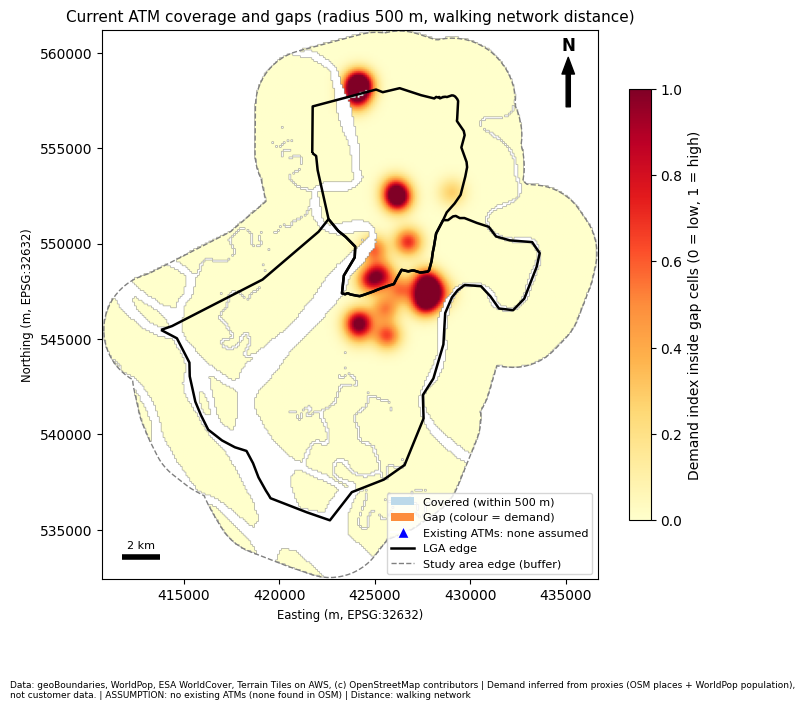

[INFO] Saved: atm_outputs/map_coverage_gaps.png
[INFO] Map check passed.


In [13]:
from matplotlib.patches import Patch                        # Legend boxes.
from matplotlib.lines import Line2D                         # Legend lines and markers.
from matplotlib.colors import ListedColormap                # A one-colour colour map.

method_label = "walking network" if DIST_STATE["method"] == "network" else "straight-line (fallback)"

fig, ax = plt.subplots(figsize=(8, 8))
covered_show = np.ma.masked_where(~COVERED, np.ones(GRID["shape"]))      # Only covered cells are drawn.
ax.imshow(covered_show, extent=grid_extent(GRID), origin="upper",
          cmap=ListedColormap(["#bcd9ea"]), vmin=0, vmax=1)               # Pale blue for covered cells.
gap_show = np.ma.masked_where(~GAP, DEMAND)                               # Only gap cells, coloured by demand.
im = ax.imshow(gap_show, extent=grid_extent(GRID), origin="upper", cmap="YlOrRd", vmin=0, vmax=1)
plt.colorbar(im, ax=ax, shrink=0.7, label="Demand index inside gap cells (0 = low, 1 = high)")
DATA["lgas"].boundary.plot(ax=ax, color="black", linewidth=1.8)           # LGA outline (candidate area).
DATA["study"].boundary.plot(ax=ax, color="grey", linewidth=1, linestyle="--")   # Buffer edge.
plot_atms(ax, color="blue", marker="^", markersize=22, edgecolor="white", linewidth=0.5)   # Existing ATMs.
handles = [Patch(facecolor="#bcd9ea", label=f"Covered (within {SERVICE_RADIUS_M} m)"),
           Patch(facecolor="#fd8d3c", label="Gap (colour = demand)"),
           Line2D([0], [0], marker="^", color="w", markerfacecolor="blue", markersize=9, label=ATM_LABEL),
           Line2D([0], [0], color="black", linewidth=1.8, label="LGA edge"),
           Line2D([0], [0], color="grey", linewidth=1, linestyle="--", label="Study area edge (buffer)")]
ax.legend(handles=handles, loc="lower right", fontsize=8)
ax.set_xlim(GRID["left"], GRID["right"])                    # Fix the limits before the helper runs.
ax.set_ylim(GRID["bottom"], GRID["top"])
add_map_furniture(ax, fig, f"Current ATM coverage and gaps (radius {SERVICE_RADIUS_M} m, {method_label} distance)",
                  CREDITS, f"{DEMAND_NOTE} | Distance: {method_label}")
MAP_GAPS = os.path.join(OUT_DIR, "map_coverage_gaps.png")
fig.savefig(MAP_GAPS, dpi=OUT_DPI, bbox_inches="tight")     # Save the picture.
plt.show()
say(f"Saved: {MAP_GAPS}")
assert os.path.exists(MAP_GAPS), "Coverage map was not saved."
say("Map check passed.")

In [14]:
# ---- Check the settings exist ----
for _nm in ("CAND_HOST_LAYERS", "CAND_DEDUP_M"):
    if _nm not in globals():
        raise NameError(f"Setting {_nm} is missing. Run the settings cell first.")
_bad = [l for l in CAND_HOST_LAYERS if l not in DATA["osm"]]
if _bad:
    raise ValueError(f"Unknown layer names in CAND_HOST_LAYERS: {_bad}. Allowed: {list(DATA['osm'])}")
assert CAND_DEDUP_M >= 0, "CAND_DEDUP_M cannot be negative."

def build_candidate_pool(data, grid, layers):
    """Join all host layers into one table. Add LGA, water, elevation and nearest-ATM facts."""
    parts = []                                              # One small table per host layer.
    for prio, layer in enumerate(CAND_HOST_LAYERS):         # Position in the list = priority (0 is first).
        g = data["osm"].get(layer)
        if (not AVAILABILITY[layer]) or g is None or len(g) == 0:
            warn(f"Host layer '{layer}' is not available. It adds NO candidates.")
            continue
        t = g[["name", "row", "col", "cx", "cy", "geometry"]].copy()   # Keep only what we need.
        t["host_type"], t["priority"] = layer, prio
        parts.append(t)
    if not parts:
        raise RuntimeError("Stopping: no host layers available, so there are no candidate sites.")
    pool = gpd.GeoDataFrame(pd.concat(parts, ignore_index=True), geometry="geometry", crs=CRS_METRIC)
    pool["name"] = pool["name"].fillna("(unnamed)")         # OSM places often have no name.
    pool["x"], pool["y"] = pool.geometry.x, pool.geometry.y # Exact coordinates in metres.
    rows, cols = pool["row"].values, pool["col"].values     # Grid cell of each point.
    pool["in_lga"] = pool.within(union_geoms(data["lgas"])).values     # Inside the two LGAs?
    if AVAILABILITY["landcover"]:
        pool["is_water"] = layers["water"][rows, cols]      # Is the cell water?
    else:
        pool["is_water"] = False                            # No land cover: the water filter is skipped (warned earlier).
    pool["elev_m"] = layers["elev"][rows, cols]             # Mean elevation of the cell (m). NaN = unknown.
    atms = data["osm"]["atms"]
    if atms is None or len(atms) == 0:
        pool["atm_dist_m"] = NO_ATM_DIST_M                  # No ATMs assumed: nothing is close.
    else:
        d, _ = cKDTree(np.column_stack([atms.geometry.x, atms.geometry.y])).query(pool[["x", "y"]].values)
        pool["atm_dist_m"] = d                                  # Straight-line distance to the nearest existing ATM (m).
    return pool

POOL_RAW = build_candidate_pool(DATA, GRID, LAYERS)

# ---- Print counts, shapes and units ----
say(f"Candidate pool: {len(POOL_RAW)} host places (table shape {POOL_RAW.shape}). Units: metres, EPSG:32632.")
summary = (POOL_RAW.groupby("host_type")
           .agg(places=("name", "size"), inside_LGAs=("in_lga", "sum"),
                in_water=("is_water", "sum"), within_spacing=("atm_dist_m", lambda s: int((s < MIN_SPACING_M).sum())),
                unnamed=("name", lambda s: int((s == "(unnamed)").sum())))
           .reindex([l for l in CAND_HOST_LAYERS if l in POOL_RAW["host_type"].unique()]))
print("\nCANDIDATE POOL BY HOST TYPE (before filters)")
print(summary.to_string())
if AVAILABILITY["elevation"]:
    e = POOL_RAW["elev_m"]
    say(f"Elevation at host places: {e.isna().sum()} unknown, min {e.min():.1f} m, median {e.median():.1f} m, max {e.max():.1f} m")
else:
    warn("Elevation layer is missing: the flood rule cannot be applied in the next step.")
if (POOL_RAW["host_type"] == "universities").any():
    warn("University candidates are campus CENTRES, not gates. Check the exact spot in the field.")

[INFO] Candidate pool: 15 host places (table shape (15, 14)). Units: metres, EPSG:32632.

CANDIDATE POOL BY HOST TYPE (before filters)
                    places  inside_LGAs  in_water  within_spacing  unnamed
host_type                                                                 
fuel_stations            3            3         0               0        1
banks                    1            1         0               0        0
supermarkets_malls       2            2         0               0        0
markets                  3            3         0               0        0
hospitals                4            4         0               0        0
universities             2            2         0               0        0
[INFO] Elevation at host places: 0 unknown, min 19.9 m, median 45.6 m, max 60.6 m
[WARNING] University candidates are campus CENTRES, not gates. Check the exact spot in the field.


In [15]:
def apply_filters(pool):
    """Apply the five rules. Returns (pool with drop_reason, survivors, funnel table)."""
    p = pool.copy()
    p["drop_reason"] = ""                                   # Empty text = still a candidate.
    funnel = [("1. Candidate pool (all host places)", len(p))]

    def mark(mask, reason):
        """Give the reason only to places that have not been dropped yet."""
        idx = mask & (p["drop_reason"] == "")
        p.loc[idx, "drop_reason"] = reason

    def left():
        """Number of places still in the running."""
        return int((p["drop_reason"] == "").sum())

    mark(~p["in_lga"], "outside the two LGAs")
    funnel.append(("2. Inside the two LGAs", left()))
    mark(p["is_water"], "in a water cell")
    funnel.append(("3. Not in water", left()))
    mark(p["atm_dist_m"] < MIN_SPACING_M, f"closer than {MIN_SPACING_M} m to an existing ATM")
    funnel.append((f"4. At least {MIN_SPACING_M} m from an existing ATM", left()))
    n_before_flood = left()
    if AVAILABILITY["elevation"]:
        mark(p["elev_m"] < LOW_ELEV_M, f"low-lying: elevation below {LOW_ELEV_M:g} m (placeholder flood rule)")
        p["elev_unknown"] = p["elev_m"].isna()              # Kept, but flagged for the field check.
    else:
        p["elev_unknown"] = True                            # No elevation anywhere.
        warn("Flood rule SKIPPED: no elevation layer. The 'low_flood' criterion is dropped.")
    funnel.append((f"5. Elevation at least {LOW_ELEV_M:g} m (or unknown)", left()))
    n_after_flood = left()
    if n_before_flood > 0 and (n_before_flood - n_after_flood) > 0.5 * n_before_flood:
        warn(f"The flood rule removed {n_before_flood - n_after_flood} of {n_before_flood} places (more than half). "
             f"LOW_ELEV_M = {LOW_ELEV_M:g} m is a placeholder. Check it against local knowledge before trusting this.")
    # --- Duplicates: keep the first host in priority order ---
    keep = p[p["drop_reason"] == ""].sort_values(["priority", "atm_dist_m"], ascending=[True, False])
    if len(keep) > 1 and CAND_DEDUP_M > 0:
        ids = keep.index.values                             # Original row labels, in priority order.
        xy = keep[["x", "y"]].values
        tree = cKDTree(xy)
        removed = np.zeros(len(keep), dtype=bool)
        for i in range(len(keep)):
            if removed[i]:
                continue                                    # Already removed by a higher-priority neighbour.
            for j in tree.query_ball_point(xy[i], r=CAND_DEDUP_M):
                if j > i:
                    removed[j] = True                       # Later in the list = lower priority = removed.
        p.loc[ids[removed], "drop_reason"] = f"duplicate: another host within {CAND_DEDUP_M} m"
    funnel.append((f"6. After merging hosts within {CAND_DEDUP_M} m", left()))
    surv = p[p["drop_reason"] == ""].sort_values(["priority", "name"]).reset_index(drop=True)
    surv.insert(0, "cand_id", [f"C{i + 1:03d}" for i in range(len(surv))])   # Short labels: C001, C002, ...
    f = pd.DataFrame(funnel, columns=["step", "places_remaining"])
    f["removed_at_step"] = (-f["places_remaining"].diff()).fillna(0).astype(int)
    return p, surv, f

POOL, CAND, FUNNEL = apply_filters(POOL_RAW)

# ---- Print the results ----
print("\nCANDIDATE FUNNEL")
print(FUNNEL.to_string(index=False))
print("\nWHY PLACES WERE DROPPED")
print(POOL.loc[POOL["drop_reason"] != "", "drop_reason"].value_counts().to_string())
print("\nSURVIVORS BY HOST TYPE")
print(CAND["host_type"].value_counts().to_string())
say(f"Candidates kept: {len(CAND)} | flagged elevation unknown: {int(CAND['elev_unknown'].sum())} | "
    f"unnamed in OSM: {int((CAND['name'] == '(unnamed)').sum())}")
if len(CAND) < N_NEW_ATMS:
    raise RuntimeError(f"Stopping: only {len(CAND)} candidates survive, but N_NEW_ATMS = {N_NEW_ATMS}. "
                       f"Look at the drop reasons above. Options: lower MIN_SPACING_M, review LOW_ELEV_M, add host types.")
FUNNEL_CSV = os.path.join(OUT_DIR, "candidate_funnel.csv")
FUNNEL.to_csv(FUNNEL_CSV, index=False)
say(f"Saved: {FUNNEL_CSV}")

# ---- Self-tests ----
assert CAND.crs.to_epsg() == 32632, "Candidates are not in EPSG:32632."
assert CAND["cand_id"].is_unique, "Candidate ids are not unique."
assert CAND["in_lga"].all(), "A candidate is outside the LGAs."
if AVAILABILITY["landcover"]:
    assert not LAYERS["water"][CAND["row"].values, CAND["col"].values].any(), "A candidate sits in a water cell."
assert (CAND["atm_dist_m"] >= MIN_SPACING_M).all(), "A candidate is closer than MIN_SPACING_M to an existing ATM."
if AVAILABILITY["elevation"]:
    assert (CAND["elev_m"].dropna() >= LOW_ELEV_M).all(), "A candidate is below the elevation rule."
if len(CAND) > 1 and CAND_DEDUP_M > 0:
    _d, _ = cKDTree(CAND[["x", "y"]].values).query(CAND[["x", "y"]].values, k=2)
    assert (_d[:, 1] > CAND_DEDUP_M - 1e-6).all(), "Two candidates are closer than CAND_DEDUP_M."
assert FUNNEL["places_remaining"].is_monotonic_decreasing, "The funnel increased at some step."
assert (POOL["drop_reason"] == "").sum() == len(CAND), "Survivor count does not match the pool."
say("Self-tests passed: metric CRS, inside LGAs, not in water, spacing and elevation rules met, no duplicates.")


CANDIDATE FUNNEL
                                  step  places_remaining  removed_at_step
   1. Candidate pool (all host places)                15                0
                2. Inside the two LGAs                15                0
                       3. Not in water                15                0
4. At least 150 m from an existing ATM                15                0
5. Elevation at least 5 m (or unknown)                15                0
    6. After merging hosts within 25 m                15                0

WHY PLACES WERE DROPPED
Series([], )

SURVIVORS BY HOST TYPE
host_type
hospitals             4
fuel_stations         3
markets               3
supermarkets_malls    2
universities          2
banks                 1
[INFO] Candidates kept: 15 | flagged elevation unknown: 0 | unnamed in OSM: 1
[INFO] Saved: atm_outputs/candidate_funnel.csv
[INFO] Self-tests passed: metric CRS, inside LGAs, not in water, spacing and elevation rules met, no duplicates.


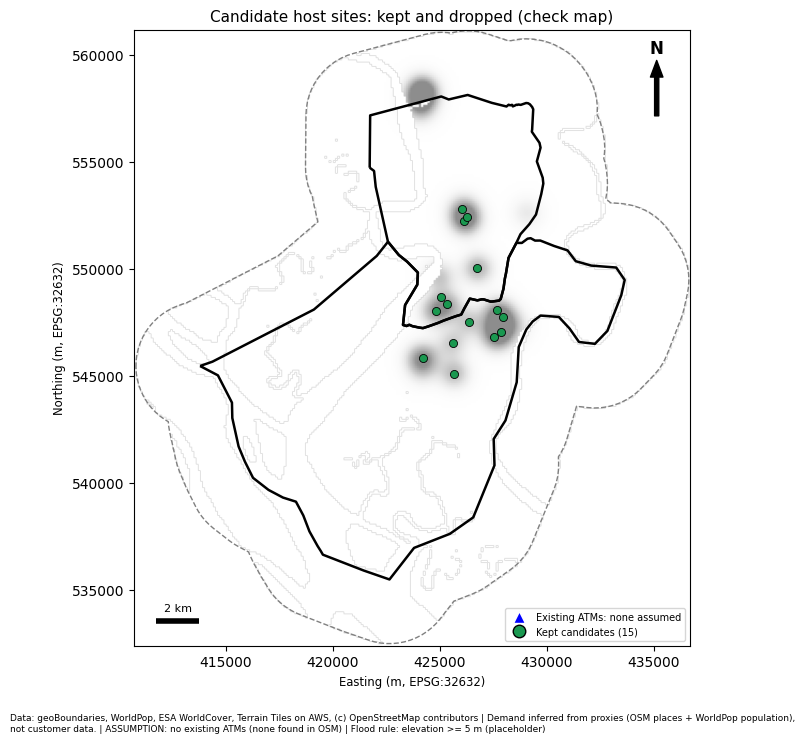

[INFO] Saved: atm_outputs/map_candidates_filtered.png
[INFO] Map check passed.


In [16]:
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(np.ma.masked_where(~VALID, DEMAND), extent=grid_extent(GRID), origin="upper",
          cmap="Greys", vmin=0, vmax=1, alpha=0.45)         # Demand in light grey, as a background.
DATA["lgas"].boundary.plot(ax=ax, color="black", linewidth=1.8)             # LGA edge (candidate area).
DATA["study"].boundary.plot(ax=ax, color="grey", linewidth=1, linestyle="--")   # Buffer edge.
plot_atms(ax, color="blue", marker="^", markersize=22, edgecolor="white", linewidth=0.5, zorder=3)
handles = [Line2D([0], [0], marker="^", color="w", markerfacecolor="blue", markersize=9, label=ATM_LABEL)]
palette = ["#d73027", "#fc8d59", "#984ea3", "#a65628", "#999999", "#e7298a"]   # Colours for drop reasons.
dropped = POOL[POOL["drop_reason"] != ""]
for color, (reason, sub) in zip(palette * 3, dropped.groupby("drop_reason")):
    sub.plot(ax=ax, color=color, marker="x", markersize=24, linewidth=1.2, zorder=4)   # One colour per reason.
    short = reason if len(reason) < 48 else reason[:45] + "..."
    handles.append(Line2D([0], [0], marker="x", color=color, linestyle="", markersize=7, label=f"Dropped: {short} ({len(sub)})"))
CAND.plot(ax=ax, color="#1a9850", marker="o", markersize=34, edgecolor="black", linewidth=0.6, zorder=5)
handles.append(Line2D([0], [0], marker="o", color="w", markerfacecolor="#1a9850", markeredgecolor="black",
                      markersize=9, label=f"Kept candidates ({len(CAND)})"))
ax.legend(handles=handles, loc="lower right", fontsize=7)
ax.set_xlim(GRID["left"], GRID["right"])                    # Fix the limits before the helper runs.
ax.set_ylim(GRID["bottom"], GRID["top"])
add_map_furniture(ax, fig, "Candidate host sites: kept and dropped (check map)", CREDITS,
                  f"{DEMAND_NOTE} | Flood rule: elevation >= {LOW_ELEV_M:g} m (placeholder)")
MAP_CAND = os.path.join(OUT_DIR, "map_candidates_filtered.png")
fig.savefig(MAP_CAND, dpi=OUT_DPI, bbox_inches="tight")
plt.show()
say(f"Saved: {MAP_CAND}")
assert os.path.exists(MAP_CAND), "Candidate check map was not saved."
say("Map check passed.")

In [17]:
RI_TABLE = {1: 0.0, 2: 0.0, 3: 0.58, 4: 0.90, 5: 1.12, 6: 1.24, 7: 1.32, 8: 1.41, 9: 1.45, 10: 1.49}   # Saaty random index.

def build_matrix(criteria, upper):
    """Build the full pairwise matrix from the upper-triangle entries. Lower half = 1 / upper."""
    n = len(criteria)
    extra = [k for k in upper if not (0 <= k[0] < k[1] < n)]    # Keys that do not fit the matrix.
    if extra:
        raise ValueError(f"AHP_UPPER has keys outside the matrix: {extra}")
    A = np.ones((n, n))                                         # Diagonal is 1.
    for i in range(n):
        for j in range(i + 1, n):
            if (i, j) not in upper:
                raise ValueError(f"Missing pair ({i}, {j}) = {criteria[i]} vs {criteria[j]} in AHP_UPPER.")
            v = float(upper[(i, j)])
            if not (1 / 9 <= v <= 9):
                raise ValueError(f"Pair ({i}, {j}) = {v} is outside the 1/9 to 9 scale.")
            A[i, j], A[j, i] = v, 1.0 / v                       # Reciprocal rule.
    return A

def ahp_weights(A):
    """Return (weights, lambda_max, CI, CR) using the principal eigenvector."""
    n = A.shape[0]
    vals, vecs = np.linalg.eig(A)                               # Eigenvalues and eigenvectors.
    k = int(np.argmax(vals.real))                               # The largest eigenvalue.
    w = np.abs(vecs[:, k].real)                                 # Its eigenvector (all one sign).
    w = w / w.sum()                                             # Scale so weights sum to 1.
    lam = float(vals[k].real)
    ci = (lam - n) / (n - 1) if n > 1 else 0.0                  # Consistency index.
    if n not in RI_TABLE:
        raise ValueError(f"No random index for a matrix of size {n}.")
    ri = RI_TABLE[n]
    cr = ci / ri if ri > 0 else 0.0                             # Matrices of size 1 or 2 are always consistent.
    return w, lam, ci, cr

# ---- Run it ----
A_FULL = build_matrix(CRITERIA, AHP_UPPER)                      # Matrix for all criteria.
KEPT = [c for c in CRITERIA if c not in DROPPED_CRITERIA]       # Criteria that have data.
if not KEPT:
    raise RuntimeError("Stopping: every criterion was dropped. Check the availability table.")
if DROPPED_CRITERIA:
    warn(f"Dropped criteria: {DROPPED_CRITERIA}. Weights are re-calculated from the remaining rows of the matrix.")
kept_idx = [CRITERIA.index(c) for c in KEPT]
A_USED = A_FULL[np.ix_(kept_idx, kept_idx)]                     # Cut the matrix down to the kept criteria.
w_full, lam_f, ci_f, cr_f = ahp_weights(A_FULL)                 # For comparison only.
w_used, LAMBDA_MAX, CI, CR = ahp_weights(A_USED)                # These are the weights we use.
WEIGHTS = dict(zip(KEPT, [float(x) for x in w_used]))           # Criterion name -> weight.

print("\nPAIRWISE MATRIX USED (row vs column: how much more important the row is)")
print(pd.DataFrame(A_USED, index=KEPT, columns=KEPT).round(2).to_string())
say(f"n = {len(KEPT)} | lambda_max = {LAMBDA_MAX:.4f} | CI = {CI:.4f} | RI = {RI_TABLE[len(KEPT)]} | CR = {CR:.4f} "
    f"(limit {AHP_MAX_CR})")
if DROPPED_CRITERIA:
    say(f"For comparison, the full {len(CRITERIA)}-criterion matrix has CR = {cr_f:.4f}.")
if CR >= AHP_MAX_CR:
    raise RuntimeError(f"Stopping: the consistency ratio {CR:.3f} is at or above {AHP_MAX_CR}. "
                       f"The pairwise judgements contradict each other. Edit AHP_UPPER in the settings cell and run again.")

wt = pd.DataFrame({"criterion": CRITERIA})
wt["status"] = ["used" if c in KEPT else "DROPPED (data missing)" for c in CRITERIA]
wt["weight"] = [WEIGHTS.get(c, 0.0) for c in CRITERIA]          # Dropped criteria get 0.
wt["weight_pct"] = (wt["weight"] * 100).round(1)
wt["weight_full_matrix"] = w_full                               # What the weights would be with no drops.
wt["consistency_ratio_used"] = CR
print("\nCRITERIA AND WEIGHTS")
print(wt.round(4).to_string(index=False))
WEIGHTS_CSV = os.path.join(OUT_DIR, "criteria_weights.csv")
wt.to_csv(WEIGHTS_CSV, index=False)
say(f"Saved: {WEIGHTS_CSV}")

# ---- Self-tests ----
assert np.isclose(sum(WEIGHTS.values()), 1.0), "Weights do not sum to 1."
assert all(v > 0 for v in WEIGHTS.values()), "A weight is not positive."
assert np.allclose(A_USED * A_USED.T, 1.0), "The matrix is not reciprocal."
assert LAMBDA_MAX >= len(KEPT) - 1e-9, "lambda_max is below n, which should not happen."
assert CR < AHP_MAX_CR, "Consistency ratio is too high."
say("Self-tests passed: weights sum to 1, matrix is reciprocal, CR is below the limit.")

[WARNING] Dropped criteria: ['gap_served', 'spacing']. Weights are re-calculated from the remaining rows of the matrix.

PAIRWISE MATRIX USED (row vs column: how much more important the row is)
                  demand_in_radius  road_frontage  activity_24h  secure_host  low_flood
demand_in_radius              1.00            2.0           2.0          3.0        3.0
road_frontage                 0.50            1.0           1.0          2.0        2.0
activity_24h                  0.50            1.0           1.0          2.0        2.0
secure_host                   0.33            0.5           0.5          1.0        1.0
low_flood                     0.33            0.5           0.5          1.0        1.0
[INFO] n = 5 | lambda_max = 5.0133 | CI = 0.0033 | RI = 1.12 | CR = 0.0030 (limit 0.1)
[INFO] For comparison, the full 7-criterion matrix has CR = 0.0108.

CRITERIA AND WEIGHTS
       criterion                 status  weight  weight_pct  weight_full_matrix  consistency_ratio_us

In [18]:
# ---- Check the settings exist and make sense ----
for _nm in ("ROAD_CLASS_SCORES", "ROAD_DEFAULT_SCORE", "FRONTAGE_SEARCH_M", "ACTIVITY_WEIGHTS", "ACTIVITY_RADIUS_M",
            "ACTIVITY_CAP", "SECURE_NEAR_M", "SECURE_NEAR_SCORE", "FLOOD_FULL_M", "FLOOD_UNKNOWN_SCORE", "SPACING_FULL_M"):
    if _nm not in globals():
        raise NameError(f"Setting {_nm} is missing. Run the settings cell first.")
assert SPACING_FULL_M > MIN_SPACING_M, "SPACING_FULL_M must be larger than MIN_SPACING_M."
assert FLOOD_FULL_M > 0 and ACTIVITY_CAP > 0, "FLOOD_FULL_M and ACTIVITY_CAP must be positive."
assert 0 <= FLOOD_UNKNOWN_SCORE <= 1 and 0 <= SECURE_NEAR_SCORE <= 1, "Scores must be between 0 and 1."

VALID_FLAT = VALID.ravel()                                  # Valid cells as one long list.
DEMAND_FLAT = DEMAND.ravel()                                # Demand as one long list (same cell order).
COVER_MAX_R = max(list(SENS_RADII_M) + [SERVICE_RADIUS_M])  # Largest radius we will ever need.

def compute_cover(cands, max_r):
    """For each candidate, store (cell indices, distances) of valid cells within max_r metres."""
    out = {}
    for cid, x, y in zip(cands["cand_id"], cands["x"], cands["y"]):
        d = distance_from_points([x], [y], cutoff=max_r).ravel()    # Walking or straight-line, as before.
        idx = np.flatnonzero(VALID_FLAT & np.isfinite(d) & (d <= max_r))
        out[cid] = (idx, d[idx])
    return out

def scale01(v):
    """Min-max scale to 0-1. If all values are equal, return 0.5 and warn."""
    v = np.asarray(v, dtype=float)
    lo, hi = np.nanmin(v), np.nanmax(v)
    if hi - lo <= 1e-12:
        warn("A criterion has the same value for every candidate, so it cannot rank them. Score set to 0.5.")
        return np.full(v.shape, 0.5)
    return (v - lo) / (hi - lo)

def radius_criteria(cover, cand_ids, radius, gap_flat):
    """Raw demand within the radius, and raw demand within the radius that lies in the current gap."""
    assert radius <= COVER_MAX_R, "Radius is larger than the stored coverage sets."
    dem, gp = [], []
    for cid in cand_ids:
        idx, d = cover[cid]
        cells = idx[d <= radius]                            # Cells within this radius.
        dem.append(DEMAND_FLAT[cells].sum())
        gp.append(DEMAND_FLAT[cells[gap_flat[cells]]].sum())    # Only the cells that are in the gap.
    return pd.DataFrame({"demand_in_radius_raw": dem, "gap_served_raw": gp}, index=list(cand_ids))

def static_criteria(cand):
    """Criteria that do not depend on the service radius. Returns a table indexed by cand_id."""
    out = pd.DataFrame(index=cand["cand_id"].values)
    pts = cand[["x", "y"]].values
    if "road_frontage" in KEPT:                             # --- Road class and frontage ---
        edges = DATA["road_edges"].copy()
        edges["hw"] = edges["highway"].astype(str).str.replace("_link", "", regex=False)   # primary_link -> primary.
        edges["rscore"] = edges["hw"].map(ROAD_CLASS_SCORES).fillna(ROAD_DEFAULT_SCORE)
        j = gpd.sjoin_nearest(cand[["cand_id", "geometry"]], edges[["hw", "rscore", "geometry"]],
                              how="left", max_distance=FRONTAGE_SEARCH_M, distance_col="road_dist_m")
        j = j.sort_values(["cand_id", "rscore"], ascending=[True, False]).drop_duplicates("cand_id")   # Ties: best class.
        j = j.set_index("cand_id").reindex(out.index)
        out["road_class"] = j["hw"].values
        out["road_dist_m"] = j["road_dist_m"].values
        out["road_frontage_raw"] = j["rscore"].fillna(0.0).values        # No road nearby = 0.
        out["road_frontage_score"] = out["road_frontage_raw"]
    if "activity_24h" in KEPT:                              # --- 24-hour activity proxies ---
        total = np.zeros(len(cand))
        for layer, w in ACTIVITY_WEIGHTS.items():
            g = DATA["osm"].get(layer)
            if g is None or len(g) == 0 or not AVAILABILITY[layer]:
                warn(f"Activity layer '{layer}' is not available. It adds nothing to 'activity_24h'.")
                continue
            tree = cKDTree(np.column_stack([g.geometry.x, g.geometry.y]))
            total += w * tree.query_ball_point(pts, r=ACTIVITY_RADIUS_M, return_length=True)   # Count within radius.
        out["activity_24h_raw"] = total
        out["activity_24h_score"] = np.clip(total / ACTIVITY_CAP, 0, 1)
    if "secure_host" in KEPT:                               # --- Secure host: bank branch or fuel station ---
        sec = [l for l in ("banks", "fuel_stations") if AVAILABILITY[l] and DATA["osm"][l] is not None and len(DATA["osm"][l]) > 0]
        xy = np.vstack([np.column_stack([DATA["osm"][l].geometry.x, DATA["osm"][l].geometry.y]) for l in sec])
        near = cKDTree(xy).query_ball_point(pts, r=SECURE_NEAR_M, return_length=True) > 0
        is_host = cand["host_type"].isin(sec).values
        out["secure_host_raw"] = np.where(is_host, 1.0, np.where(near, SECURE_NEAR_SCORE, 0.0))
        out["secure_host_score"] = out["secure_host_raw"]
    if "low_flood" in KEPT:                                 # --- Low flood exposure (placeholder rule) ---
        e = cand["elev_m"].values.astype(float)
        s = np.clip((e - LOW_ELEV_M) / FLOOD_FULL_M, 0, 1)
        out["low_flood_raw"] = e
        out["low_flood_score"] = np.where(np.isnan(e), FLOOD_UNKNOWN_SCORE, s)   # Unknown = neutral.
    if "spacing" in KEPT:                                   # --- Spacing from existing ATMs ---
        d = cand["atm_dist_m"].values.astype(float)
        out["spacing_raw"] = d
        out["spacing_score"] = np.clip((d - MIN_SPACING_M) / (SPACING_FULL_M - MIN_SPACING_M), 0, 1)
    return out

# ---- Step 1: coverage sets for every candidate ----
import time
t0 = time.time()
try:
    COVER = compute_cover(CAND, COVER_MAX_R)
except Exception as e:
    if DIST_STATE["method"] != "network":
        raise                                               # Straight-line failed too: nothing to fall back to.
    warn(f"Walking distance failed for candidates ({type(e).__name__}: {str(e)[:100]}). "
         f"Switching EVERYTHING to STRAIGHT-LINE distance and recomputing the baseline coverage. "
         f"Re-run the coverage map cell if you want it redrawn.")
    DIST_STATE["method"] = "straight-line"
    DIST, DIST_LINE = baseline_distance(ATM_X, ATM_Y, VALID)
    GAP_TABLE, COVERED, GAP = summarise_gap(DIST, SERVICE_RADIUS_M, VALID, LAYERS, DEMAND, AVAILABILITY["population"])
    GAP_TABLE.to_csv(GAP_CSV, index=False)
    COVER = compute_cover(CAND, COVER_MAX_R)
say(f"Coverage sets built for {len(COVER)} candidates in {time.time() - t0:.1f} s | method: {DIST_STATE['method']} | "
    f"largest radius {COVER_MAX_R} m")
n_empty = sum(1 for idx, _ in COVER.values() if len(idx) == 0)
if n_empty:
    warn(f"{n_empty} candidates cover no cells (for example, their road component is cut off). They will score low.")
say(f"Median cells within {COVER_MAX_R} m of a candidate: {int(np.median([len(i) for i, _ in COVER.values()]))}")

# ---- Step 2: all criteria ----
GAP_FLAT = GAP.ravel()                                      # Gap at SERVICE_RADIUS_M, as one long list.
CRIT = static_criteria(CAND).join(radius_criteria(COVER, CAND["cand_id"], SERVICE_RADIUS_M, GAP_FLAT))
for _c in ("demand_in_radius", "gap_served"):
    if _c in KEPT:
        CRIT[_c + "_score"] = scale01(CRIT[_c + "_raw"].values)

# ---- Print a summary: raw values and scores ----
rows = []
for c in KEPT:
    r, s = CRIT[c + "_raw"], CRIT[c + "_score"]
    rows.append({"criterion": c, "raw_min": r.min(), "raw_median": r.median(), "raw_max": r.max(),
                 "score_min": s.min(), "score_median": s.median(), "score_max": s.max()})
print("\nCRITERIA SUMMARY (raw units: demand index, class score, weighted count, 0-1, metres, metres)")
print(pd.DataFrame(rows).round(2).to_string(index=False))
say(f"Criteria table shape: {CRIT.shape} (candidates x columns).")
if "low_flood" in KEPT:
    say(f"Candidates with unknown elevation (neutral flood score): {int(CAND['elev_unknown'].sum())}")
if "road_frontage" in KEPT:
    say(f"Candidates with no mapped road within {FRONTAGE_SEARCH_M} m: {int(CRIT['road_class'].isna().sum())}")

# ---- Self-tests ----
assert len(CRIT) == len(CAND) and CRIT.index.is_unique, "Criteria table does not match the candidates."
for c in KEPT:
    s = CRIT[c + "_score"]
    assert s.notna().all(), f"NaN score in {c}."
    assert s.min() >= -1e-9 and s.max() <= 1 + 1e-9, f"Score outside 0-1 in {c}."
assert (CRIT["gap_served_raw"] <= CRIT["demand_in_radius_raw"] + 1e-9).all(), "Gap demand is above total demand within the radius."
for _cid in list(CAND["cand_id"])[:3]:                      # Spot-check three candidates.
    _idx, _d = COVER[_cid]
    _row = CAND[CAND["cand_id"] == _cid].iloc[0]
    _line = straight_dist([_row["x"]], [_row["y"]], DIST_STATE["grid_xy"], DIST_STATE["shape"]).ravel()
    assert (_d <= COVER_MAX_R + 1e-6).all() and (_d >= _line[_idx] - 1e-6).all(), "Coverage distances are not valid."
say("Self-tests passed: scores are 0-1, gap demand <= total demand, walking distance >= straight-line distance.")

[INFO] Coverage sets built for 15 candidates in 0.3 s | method: network | largest radius 1000 m
[INFO] Median cells within 1000 m of a candidate: 108

CRITERIA SUMMARY (raw units: demand index, class score, weighted count, 0-1, metres, metres)
       criterion  raw_min  raw_median  raw_max  score_min  score_median  score_max
demand_in_radius     3.53       12.00    33.44        0.0          0.28       1.00
   road_frontage     0.00        0.30     0.60        0.0          0.30       0.60
    activity_24h     0.00        0.00     2.00        0.0          0.00       0.67
     secure_host     0.00        0.00     1.00        0.0          0.00       1.00
       low_flood    19.92       45.61    60.61        1.0          1.00       1.00
[INFO] Criteria table shape: (15, 13) (candidates x columns).
[INFO] Candidates with unknown elevation (neutral flood score): 0
[INFO] Candidates with no mapped road within 50 m: 3
[INFO] Self-tests passed: scores are 0-1, gap demand <= total demand, walking


WEIGHTS USED
  demand_in_radius    36.9 %
  activity_24h        20.6 %
  road_frontage       20.6 %
  secure_host         10.9 %
  low_flood           10.9 %

TOP 15 CANDIDATES (suitability 0-100)
 1  C008  Market                     markets             60.2  Strong: demand index 33.4 within 500 m; on a 'tertiary' road (29 m away) | Weak: 0.0 weighted fuel/hospital/transport places within 300 m
 2  C001  (unnamed)                  fuel_stations       59.7  Strong: demand index 23.6 within 500 m; host is a fuel station | Weak: on a 'service' road (4 m away)
 3  C003  Udddy King Petol Station   fuel_stations       52.2  Strong: 2.0 weighted fuel/hospital/transport places within 300 m; host is a fuel station | Weak: demand index 12.0 within 500 m
 4  C002  Eterna Plc                 fuel_stations       51.0  Strong: 2.0 weighted fuel/hospital/transport places within 300 m; host is a fuel station | Weak: demand index 11.0 within 500 m
 5  C004  Central Bank of Nigeria, C banks            

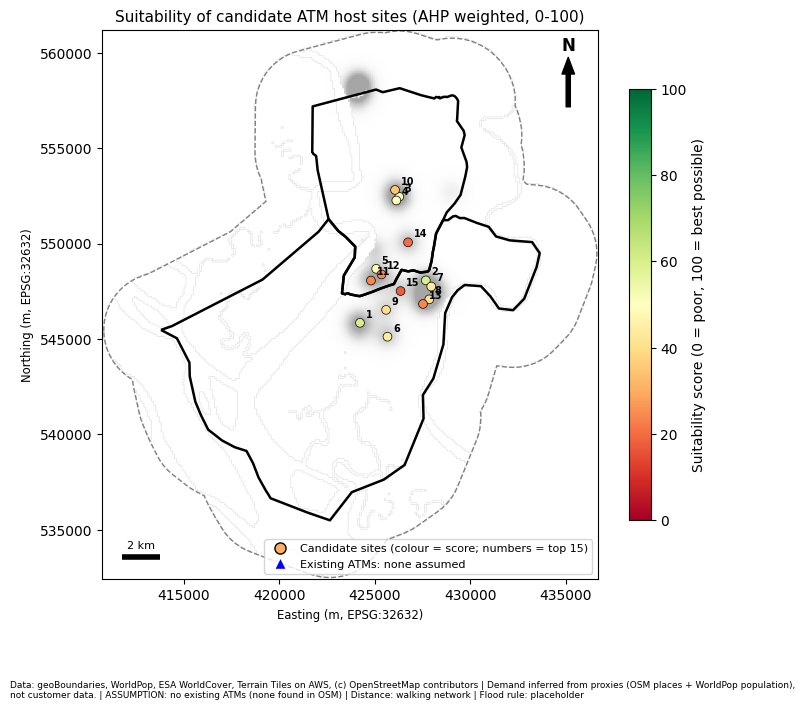

[INFO] Saved: atm_outputs/map_suitability.png
[INFO] Self-tests passed: weights sum to 1, scores are 0-100, ranking is sorted, perfect scores give 100.


In [19]:
def suitability(crit, weights):
    """Weighted linear combination of criterion scores, on a 0-100 scale."""
    total = np.zeros(len(crit))
    for c, w in weights.items():
        total += w * crit[c + "_score"].values              # Weight x score for each criterion.
    return 100.0 * total

def describe(c, r):
    """Plain-English phrase for one criterion, using the real values in row r."""
    if c == "demand_in_radius":
        return f"demand index {r['demand_in_radius_raw']:.1f} within {SERVICE_RADIUS_M} m"
    if c == "gap_served":
        return f"{r['gap_served_raw']:.1f} demand index in the current gap within reach"
    if c == "road_frontage":
        if pd.isna(r.get("road_class")):
            return f"no mapped road within {FRONTAGE_SEARCH_M} m"
        return f"on a '{r['road_class']}' road ({r['road_dist_m']:.0f} m away)"
    if c == "activity_24h":
        return f"{r['activity_24h_raw']:.1f} weighted fuel/hospital/transport places within {ACTIVITY_RADIUS_M} m"
    if c == "secure_host":
        if r["host_type"] == "banks": return "host is a bank branch"
        if r["host_type"] == "fuel_stations": return "host is a fuel station"
        return (f"bank or fuel station within {SECURE_NEAR_M} m" if r["secure_host_score"] > 0
                else f"no bank or fuel station within {SECURE_NEAR_M} m")
    if c == "low_flood":
        return ("elevation unknown (neutral score)" if pd.isna(r["elev_m"])
                else f"elevation {r['elev_m']:.1f} m (rule: at least {LOW_ELEV_M:g} m)")
    if c == "spacing":
        return f"{r['spacing_raw']:.0f} m from the nearest existing ATM"
    return c

def reason_text(r, weights):
    """Build the reason: the two biggest point contributors and the weakest criterion."""
    contrib = {c: weights[c] * r[c + "_score"] * 100 for c in weights}       # Points each criterion adds.
    best = sorted(contrib, key=contrib.get, reverse=True)[:2]
    worst = min(weights, key=lambda c: r[c + "_score"])
    txt = "Strong: " + "; ".join(describe(c, r) for c in best)
    if worst not in best:
        txt += " | Weak: " + describe(worst, r)
    return txt

# ---- Score and rank ----
SC = CAND.merge(CRIT, left_on="cand_id", right_index=True)  # Candidates plus all criteria (stays a GeoDataFrame).
SC["suitability"] = suitability(SC, WEIGHTS)
SC = SC.sort_values(["suitability", "demand_in_radius_raw"], ascending=[False, False]).reset_index(drop=True)
SC["rank"] = np.arange(1, len(SC) + 1)
SC["reason"] = SC.apply(lambda r: reason_text(r, WEIGHTS), axis=1)
_ll = SC.to_crs(CRS_LATLON)                                 # Degrees, for the field team.
SC["lon"], SC["lat"] = _ll.geometry.x.values, _ll.geometry.y.values

# ---- Print weights, ranking and a score summary ----
print("\nWEIGHTS USED")
for c, w in sorted(WEIGHTS.items(), key=lambda kv: -kv[1]):
    print(f"  {c:<18} {w * 100:5.1f} %")
print("\nTOP 15 CANDIDATES (suitability 0-100)")
for _, r in SC.head(15).iterrows():
    print(f"{r['rank']:>2}  {r['cand_id']}  {str(r['name'])[:26]:<26} {r['host_type']:<18} {r['suitability']:5.1f}  {r['reason']}")
say(f"Suitability of all {len(SC)} candidates: min {SC['suitability'].min():.1f}, median {SC['suitability'].median():.1f}, "
    f"max {SC['suitability'].max():.1f}")
say("Candidates by host type among the top 15: " + ", ".join(f"{k}={v}" for k, v in SC.head(15)["host_type"].value_counts().items()))

# ---- Save the tables ----
score_cols = [c + "_score" for c in KEPT]
top_cols = ["rank", "cand_id", "name", "host_type", "suitability"] + score_cols + ["reason", "lon", "lat", "x", "y"]
TOP15 = SC.head(15)[top_cols].copy()
SCORES_CSV = os.path.join(OUT_DIR, "candidate_scores_all.csv")
TOP15_CSV = os.path.join(OUT_DIR, "top15_candidates.csv")
pd.DataFrame(SC.drop(columns="geometry")).round(4).to_csv(SCORES_CSV, index=False)
TOP15.round(4).to_csv(TOP15_CSV, index=False)
say(f"Saved: {SCORES_CSV} and {TOP15_CSV}")

# ---- Suitability map ----
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(np.ma.masked_where(~VALID, DEMAND), extent=grid_extent(GRID), origin="upper",
          cmap="Greys", vmin=0, vmax=1, alpha=0.35)         # Demand in light grey, as a background.
DATA["lgas"].boundary.plot(ax=ax, color="black", linewidth=1.8)
DATA["study"].boundary.plot(ax=ax, color="grey", linewidth=1, linestyle="--")
plot_atms(ax, color="blue", marker="^", markersize=20, edgecolor="white", linewidth=0.5, zorder=3)
pts = ax.scatter(SC["x"], SC["y"], c=SC["suitability"], cmap="RdYlGn", vmin=0, vmax=100, s=40,
                 edgecolor="black", linewidth=0.5, zorder=5)
plt.colorbar(pts, ax=ax, shrink=0.7, label="Suitability score (0 = poor, 100 = best possible)")
for _, r in SC.head(15).iterrows():                         # Label the top 15 with their rank.
    ax.annotate(str(int(r["rank"])), (r["x"], r["y"]), xytext=(4, 4), textcoords="offset points",
                fontsize=7, fontweight="bold", zorder=6)
ax.legend(handles=[Line2D([0], [0], marker="o", color="w", markerfacecolor="#fdae61", markeredgecolor="black", markersize=8,
                          label="Candidate sites (colour = score; numbers = top 15)"),
                   Line2D([0], [0], marker="^", color="w", markerfacecolor="blue", markersize=9, label=ATM_LABEL)],
          loc="lower right", fontsize=8)
ax.set_xlim(GRID["left"], GRID["right"])
ax.set_ylim(GRID["bottom"], GRID["top"])
_method = "walking network" if DIST_STATE["method"] == "network" else "straight-line (fallback)"
add_map_furniture(ax, fig, "Suitability of candidate ATM host sites (AHP weighted, 0-100)", CREDITS,
                  f"{DEMAND_NOTE} | Distance: {_method} | Flood rule: placeholder")
MAP_SUIT = os.path.join(OUT_DIR, "map_suitability.png")
fig.savefig(MAP_SUIT, dpi=OUT_DPI, bbox_inches="tight")
plt.show()
say(f"Saved: {MAP_SUIT}")

# ---- Self-tests ----
assert np.isclose(sum(WEIGHTS.values()), 1.0), "Weights do not sum to 1."
assert len(SC) == len(CAND) and SC["cand_id"].is_unique, "Scored table does not match the candidates."
assert SC["suitability"].between(0, 100 + 1e-9).all(), "A suitability score is outside 0-100."
assert SC["suitability"].is_monotonic_decreasing, "Ranking is not sorted by score."
_ones = pd.DataFrame({c + "_score": [1.0] for c in KEPT})
assert np.isclose(suitability(_ones, WEIGHTS)[0], 100.0), "Perfect scores should give exactly 100."
assert SC["reason"].str.len().gt(0).all(), "A reason is empty."
assert len(TOP15) == min(15, len(SC)) and os.path.exists(MAP_SUIT) and os.path.exists(TOP15_CSV), "An output file is missing."
say("Self-tests passed: weights sum to 1, scores are 0-100, ranking is sorted, perfect scores give 100.")

In [20]:
# ---- Check the new setting exists ----
if "MIN_SUITABILITY" not in globals():
    raise NameError("Setting MIN_SUITABILITY is missing. Run the settings cell first.")
assert 0 <= MIN_SUITABILITY <= 100, "MIN_SUITABILITY must be between 0 and 100."

# ---- Flat (one long list) versions of the grid layers. Cell order matches the COVER indices. ----
POP_FLAT = LAYERS["pop"].ravel().astype("float64")          # People per cell.
LGA_FLAT = LAYERS["in_lga"].ravel()                         # True inside the two LGAs.
COVERED_FLAT = COVERED.ravel()                              # True where existing ATMs already cover.
HAS_POP = AVAILABILITY["population"]                        # False means population columns will show NaN.

def cells_within(cover, cid, radius):
    """Cell indices within `radius` metres of candidate `cid`, from the stored coverage sets."""
    idx, d = cover[cid]
    return idx[d <= radius]

def greedy_select(cover, cand, radius, n, covered_flat, min_spacing, min_suit=0.0, score_col="suitability"):
    """Greedy maximal coverage. Pick up to n sites, each adding the most uncovered demand.
    cand needs columns: cand_id, x, y and score_col. Returns one row per pick."""
    assert radius <= COVER_MAX_R, "Radius is larger than the stored coverage sets."
    ids = sorted(cand["cand_id"])                           # Sorted ids make ties repeatable.
    suit = dict(zip(cand["cand_id"], cand[score_col].astype(float)))   # Score of each candidate.
    X = dict(zip(cand["cand_id"], cand["x"].astype(float)))            # Exact x (m).
    Y = dict(zip(cand["cand_id"], cand["y"].astype(float)))            # Exact y (m).
    cells = {cid: cells_within(cover, cid, radius) for cid in ids}     # Cells each site reaches.
    eligible = [cid for cid in ids if suit[cid] >= min_suit]           # Apply the suitability floor.
    if len(eligible) < n:
        warn(f"Only {len(eligible)} candidates pass MIN_SUITABILITY = {min_suit:g}, fewer than N = {n}.")
    uncovered = (~covered_flat) & VALID_FLAT                # Cells still needing coverage.
    rows, cum_d, cum_p = [], 0.0, 0.0
    for step in range(1, n + 1):
        best_id, best_key = None, None
        for cid in eligible:                                # Try every eligible site.
            c = cells[cid]
            gain = DEMAND_FLAT[c[uncovered[c]]].sum()       # Uncovered demand this site would add.
            key = (round(float(gain), 9), suit[cid])        # Gain first, then suitability as the tie-break.
            if best_key is None or key > best_key:          # Strictly better only, so earlier ids win exact ties.
                best_id, best_key = cid, key
        if best_id is None or best_key[0] <= 0:
            warn(f"Stopped after {step - 1} picks: no eligible site adds any uncovered demand.")
            break
        c = cells[best_id]
        new = c[uncovered[c]]                               # Cells this pick covers for the first time.
        reach = float(DEMAND_FLAT[c].sum())                 # All demand within its radius.
        gain_d = float(DEMAND_FLAT[new].sum())              # New demand covered.
        gain_p = float(POP_FLAT[new].sum())                 # New people covered.
        cum_d, cum_p = cum_d + gain_d, cum_p + gain_p
        rows.append({"step": step, "cand_id": best_id, "new_cells": int(len(new)),
                     "reach_demand": reach, "gain_demand": gain_d,
                     "already_covered_demand": reach - gain_d,        # Overlap with earlier coverage.
                     "gain_demand_lga": float(DEMAND_FLAT[new[LGA_FLAT[new]]].sum()),
                     "gain_pop": gain_p, "gain_pop_lga": float(POP_FLAT[new[LGA_FLAT[new]]].sum()),
                     "cum_demand": cum_d, "cum_pop": cum_p})
        uncovered[new] = False                              # Update coverage after the pick.
        bx, by = X[best_id], Y[best_id]
        eligible = [cid for cid in eligible                 # Drop the pick and anything too close to it.
                    if cid != best_id and np.hypot(X[cid] - bx, Y[cid] - by) >= min_spacing]
    return pd.DataFrame(rows)

def evaluate_selection(cover, ids, radius, covered_flat, scope):
    """Measure what a set of sites adds inside `scope` (a flat True/False mask).
    Works for any set of sites, so the sensitivity step can reuse it."""
    count = np.zeros(VALID_FLAT.size, dtype=int)            # How many chosen sites reach each cell.
    for cid in ids:
        count[cells_within(cover, cid, radius)] += 1
    union = count > 0                                       # Cells reached by at least one chosen site.
    new = union & ~covered_flat & scope                     # Reached and not covered before.
    reach_sum = float((DEMAND_FLAT * count * scope).sum())  # Demand counted once per site that reaches it.
    union_dem = float(DEMAND_FLAT[union & scope].sum())     # Demand reached, counted once.
    new_dem = float(DEMAND_FLAT[new].sum())                 # Demand newly covered.
    return {"union": union, "scope_cells": int(scope.sum()),
            "demand_total": float(DEMAND_FLAT[scope].sum()),
            "demand_before": float(DEMAND_FLAT[covered_flat & scope].sum()),
            "demand_after": float(DEMAND_FLAT[(covered_flat | union) & scope].sum()),
            "demand_new": new_dem,
            "pop_total": float(POP_FLAT[scope].sum()),
            "pop_before": float(POP_FLAT[covered_flat & scope].sum()),
            "pop_after": float(POP_FLAT[(covered_flat | union) & scope].sum()),
            "pop_new": float(POP_FLAT[new].sum()),
            "reach_demand_sum": reach_sum,
            "overlap_among_new": reach_sum - union_dem,     # Demand reached by two or more new sites.
            "overlap_with_existing": union_dem - new_dem,   # Demand that existing ATMs already covered.
            "cells_uncovered_before": int((scope & ~covered_flat).sum()),
            "cells_uncovered_after": int((scope & ~(covered_flat | union)).sum())}

say("Greedy tools defined: cells_within, greedy_select, evaluate_selection.")

[INFO] Greedy tools defined: cells_within, greedy_select, evaluate_selection.


In [21]:
# ---- Run the greedy selection ----
SEL = greedy_select(COVER, SC, SERVICE_RADIUS_M, N_NEW_ATMS, COVERED_FLAT, MIN_SPACING_M, MIN_SUITABILITY)
if len(SEL) == 0:
    raise RuntimeError("Stopping: the greedy method picked no sites. Lower MIN_SUITABILITY or check the gap map.")
if len(SEL) < N_NEW_ATMS:
    warn(f"Only {len(SEL)} sites were picked, not N_NEW_ATMS = {N_NEW_ATMS}. Extra sites would add no uncovered demand.")

# ---- Join the picks to names, scores and reasons ----
info_cols = ["cand_id", "name", "host_type", "suitability", "rank", "lon", "lat", "x", "y", "reason", "geometry"]
CHOSEN = SC[info_cols].merge(SEL, on="cand_id").sort_values("step").reset_index(drop=True)
CHOSEN = CHOSEN.rename(columns={"rank": "suitability_rank"})
CHOSEN = gpd.GeoDataFrame(CHOSEN, geometry="geometry", crs=CRS_METRIC)
CHOSEN_IDS = list(CHOSEN["cand_id"])

# ---- Measure coverage before and after, for the LGAs and for the whole study area ----
SCOPES = {"LGAs (candidate area)": VALID_FLAT & LGA_FLAT, "Study area incl. buffer": VALID_FLAT}
EV = {name: evaluate_selection(COVER, CHOSEN_IDS, SERVICE_RADIUS_M, COVERED_FLAT, m) for name, m in SCOPES.items()}
cell_km2 = GRID_M ** 2 / 1e6                                # Area of one cell in km2.
rows = []
for name, e in EV.items():
    waste = e["overlap_among_new"] + e["overlap_with_existing"]       # Reach that added nothing new.
    rows.append({
        "scope": name, "n_new_sites": len(CHOSEN), "radius_m": SERVICE_RADIUS_M, "distance_method": DIST_STATE["method"],
        "demand_total_index": e["demand_total"],
        "demand_covered_before_index": e["demand_before"], "demand_covered_after_index": e["demand_after"],
        "demand_covered_before_pct": pct(e["demand_before"], e["demand_total"]),
        "demand_covered_after_pct": pct(e["demand_after"], e["demand_total"]),
        "extra_demand_covered_index": e["demand_new"],
        "population_total": e["pop_total"] if HAS_POP else np.nan,
        "population_covered_before": e["pop_before"] if HAS_POP else np.nan,
        "population_covered_after": e["pop_after"] if HAS_POP else np.nan,
        "population_covered_before_pct": pct(e["pop_before"], e["pop_total"]) if HAS_POP else np.nan,
        "population_covered_after_pct": pct(e["pop_after"], e["pop_total"]) if HAS_POP else np.nan,
        "extra_population_covered": e["pop_new"] if HAS_POP else np.nan,
        "overlap_with_existing_index": e["overlap_with_existing"],
        "overlap_among_new_sites_index": e["overlap_among_new"],
        "overlap_pct_of_new_site_reach": pct(waste, e["reach_demand_sum"]),
        "gap_area_before_km2": e["cells_uncovered_before"] * cell_km2,
        "gap_area_after_km2": e["cells_uncovered_after"] * cell_km2})
COV_TABLE = pd.DataFrame(rows)

# ---- Print the results ----
print("\nCHOSEN SITES (greedy order; gains in demand index units and people)")
for _, r in CHOSEN.iterrows():
    print(f"{int(r['step']):>2}  {r['cand_id']}  {str(r['name'])[:24]:<24} {r['host_type']:<18} suit {r['suitability']:5.1f} "
          f"(rank {int(r['suitability_rank']):>3})  +demand {r['gain_demand']:7.1f}  +people {r['gain_pop']:8.0f}  "
          f"already-covered {r['already_covered_demand']:6.1f}")
print("\nCOVERAGE BEFORE AND AFTER")
print(COV_TABLE.round(2).set_index("scope").T.to_string())
_topn = set(SC.head(len(CHOSEN))["cand_id"])
say(f"{len(set(CHOSEN_IDS) & _topn)} of the {len(CHOSEN)} chosen sites are also in the top {len(CHOSEN)} by suitability score alone.")
say(f"Distance method: {DIST_STATE['method']} | radius {SERVICE_RADIUS_M} m | min spacing {MIN_SPACING_M} m")
if not HAS_POP:
    warn("No population layer: population columns are NaN.")

# ---- Save ----
SELECTED_CSV = os.path.join(OUT_DIR, "selected_sites.csv")
COVERAGE_CSV = os.path.join(OUT_DIR, "coverage_before_after.csv")
pd.DataFrame(CHOSEN.drop(columns="geometry")).round(4).to_csv(SELECTED_CSV, index=False)
COV_TABLE.round(4).to_csv(COVERAGE_CSV, index=False)
say(f"Saved: {SELECTED_CSV} and {COVERAGE_CSV}")

# ---- Self-tests ----
_s, _l = EV["Study area incl. buffer"], EV["LGAs (candidate area)"]
assert 0 < len(CHOSEN) <= N_NEW_ATMS and CHOSEN["cand_id"].is_unique, "Wrong number of chosen sites, or duplicates."
assert CHOSEN["cand_id"].isin(CAND["cand_id"]).all(), "A chosen site is not in the candidate list."
assert (SEL["gain_demand"] > 0).all(), "A pick added no demand."
assert (np.diff(SEL["gain_demand"].values) <= 1e-9).all(), "Greedy gains should never increase from one pick to the next."
for _e in (_s, _l):                                         # Coverage after must be at least coverage before.
    assert _e["demand_after"] >= _e["demand_before"] - 1e-9, "Demand coverage got worse."
    assert _e["pop_after"] >= _e["pop_before"] - 1e-9, "Population coverage got worse."
    assert _e["overlap_among_new"] >= -1e-9 and _e["overlap_with_existing"] >= -1e-9, "Negative overlap."
    assert _e["cells_uncovered_after"] <= _e["cells_uncovered_before"], "Uncovered cells increased."
assert np.isclose(SEL["gain_demand"].sum(), _s["demand_new"]), "Greedy gains do not match the independent re-measurement (study area)."
assert np.isclose(SEL["gain_demand_lga"].sum(), _l["demand_new"]), "Greedy gains do not match the independent re-measurement (LGAs)."
assert np.isclose(_s["demand_before"], DEMAND[COVERED].sum()), "Coverage before does not match the gap analysis."
if len(ATMS) > 0:
    _d_atm, _ = cKDTree(np.column_stack([ATM_X, ATM_Y])).query(CHOSEN[["x", "y"]].values)
    assert (_d_atm >= MIN_SPACING_M - 1e-6).all(), "A chosen site is closer than MIN_SPACING_M to an existing ATM."
if len(CHOSEN) > 1:
    _dd, _ = cKDTree(CHOSEN[["x", "y"]].values).query(CHOSEN[["x", "y"]].values, k=2)
    assert (_dd[:, 1] >= MIN_SPACING_M - 1e-6).all(), "Two chosen sites are closer than MIN_SPACING_M."
assert (CHOSEN["in_lga"].all() if "in_lga" in CHOSEN.columns else CHOSEN.within(union_geoms(DATA["lgas"])).all()), "A chosen site is outside the LGAs."
assert (CHOSEN["suitability"] >= MIN_SUITABILITY - 1e-9).all(), "A chosen site is below MIN_SUITABILITY."
say("Self-tests passed: coverage after >= before, greedy gains never rise, spacing from existing ATMs and between new sites holds, "
    "and the independent re-measurement matches.")


CHOSEN SITES (greedy order; gains in demand index units and people)
 1  C008  Market                   markets            suit  60.2 (rank   1)  +demand    33.4  +people        0  already-covered    0.0
 2  C015  University of Cross Rive universities       suit  44.3 (rank   6)  +demand    23.9  +people        0  already-covered    0.0
 3  C001  (unnamed)                fuel_stations      suit  59.7 (rank   2)  +demand    23.6  +people        0  already-covered    0.0
 4  C014  University of Calabar    universities       suit  41.1 (rank   8)  +demand    23.0  +people        0  already-covered    0.0
 5  C004  Central Bank of Nigeria, banks              suit  48.5 (rank   5)  +demand    20.1  +people        0  already-covered    0.0
 6  C013  University of Calabar Te hospitals          suit  44.3 (rank   7)  +demand    17.0  +people        0  already-covered    3.0
 7  C003  Udddy King Petol Station fuel_stations      suit  52.2 (rank   3)  +demand    12.0  +people        0  already-c

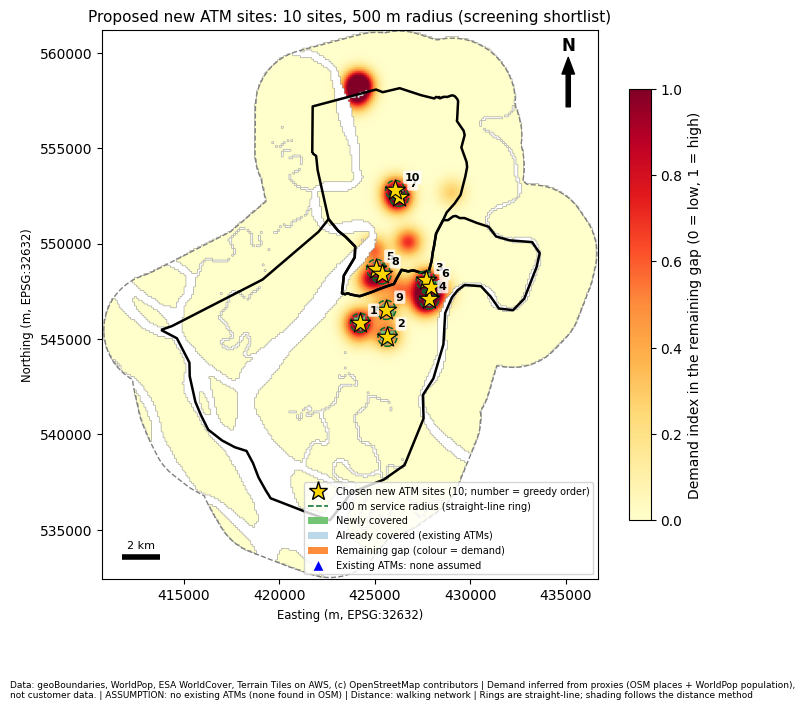

[INFO] Saved: atm_outputs/map_final_sites.png
[INFO] Map check passed: new, old and remaining cells do not overlap, and the shading matches the coverage table.


In [22]:
from matplotlib.patches import Circle                       # For the service-radius rings.

_union = EV["Study area incl. buffer"]["union"]             # Cells reached by the chosen sites.
NEW_MASK = (_union & ~COVERED_FLAT).reshape(GRID["shape"]) & VALID    # Newly covered cells.
REMAIN_GAP = GAP & ~NEW_MASK                                # Gap that is still left.
_method = "walking network" if DIST_STATE["method"] == "network" else "straight-line (fallback)"

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(np.ma.masked_where(~COVERED, np.ones(GRID["shape"])), extent=grid_extent(GRID), origin="upper",
          cmap=ListedColormap(["#bcd9ea"]), vmin=0, vmax=1)                       # Existing coverage.
ax.imshow(np.ma.masked_where(~NEW_MASK, np.ones(GRID["shape"])), extent=grid_extent(GRID), origin="upper",
          cmap=ListedColormap(["#74c476"]), vmin=0, vmax=1)                       # New coverage.
im = ax.imshow(np.ma.masked_where(~REMAIN_GAP, DEMAND), extent=grid_extent(GRID), origin="upper",
               cmap="YlOrRd", vmin=0, vmax=1)                                     # Remaining gap.
plt.colorbar(im, ax=ax, shrink=0.7, label="Demand index in the remaining gap (0 = low, 1 = high)")
DATA["lgas"].boundary.plot(ax=ax, color="black", linewidth=1.8)
DATA["study"].boundary.plot(ax=ax, color="grey", linewidth=1, linestyle="--")
plot_atms(ax, color="blue", marker="^", markersize=20, edgecolor="white", linewidth=0.5, zorder=3)
for _, r in CHOSEN.iterrows():
    ax.add_patch(Circle((r["x"], r["y"]), SERVICE_RADIUS_M, fill=False, edgecolor="#006d2c",
                        linestyle="--", linewidth=1.1, zorder=4))                 # Service-radius ring.
ax.scatter(CHOSEN["x"], CHOSEN["y"], marker="*", s=230, color="gold", edgecolor="black", linewidth=0.8, zorder=6)
for _, r in CHOSEN.iterrows():                              # Number the stars in greedy order.
    ax.annotate(str(int(r["step"])), (r["x"], r["y"]), xytext=(7, 7), textcoords="offset points",
                fontsize=8, fontweight="bold", zorder=7,
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))
ax.legend(handles=[Line2D([0], [0], marker="*", color="w", markerfacecolor="gold", markeredgecolor="black", markersize=14,
                          label=f"Chosen new ATM sites ({len(CHOSEN)}; number = greedy order)"),
                   Line2D([0], [0], color="#006d2c", linestyle="--", linewidth=1.1, label=f"{SERVICE_RADIUS_M} m service radius (straight-line ring)"),
                   Patch(facecolor="#74c476", label="Newly covered"),
                   Patch(facecolor="#bcd9ea", label="Already covered (existing ATMs)"),
                   Patch(facecolor="#fd8d3c", label="Remaining gap (colour = demand)"),
                   Line2D([0], [0], marker="^", color="w", markerfacecolor="blue", markersize=9, label=ATM_LABEL)],
          loc="lower right", fontsize=7)
ax.set_xlim(GRID["left"], GRID["right"])                    # Fix the limits before the helper runs.
ax.set_ylim(GRID["bottom"], GRID["top"])
add_map_furniture(ax, fig, f"Proposed new ATM sites: {len(CHOSEN)} sites, {SERVICE_RADIUS_M} m radius (screening shortlist)", CREDITS,
                  f"{DEMAND_NOTE} | Distance: {_method} | Rings are straight-line; shading follows the distance method")
MAP_FINAL = os.path.join(OUT_DIR, "map_final_sites.png")
fig.savefig(MAP_FINAL, dpi=OUT_DPI, bbox_inches="tight")
plt.show()
say(f"Saved: {MAP_FINAL}")

# ---- Self-tests ----
assert os.path.exists(MAP_FINAL), "Final map was not saved."
assert not (NEW_MASK & COVERED).any(), "A newly covered cell was already covered."
assert not (REMAIN_GAP & NEW_MASK).any(), "A cell is both remaining gap and newly covered."
assert np.isclose(DEMAND[NEW_MASK].sum(), EV["Study area incl. buffer"]["demand_new"]), "Map shading does not match the coverage table."
say("Map check passed: new, old and remaining cells do not overlap, and the shading matches the coverage table.")

In [23]:
# ---- Check the settings exist and make sense ----
for _nm in ("SENS_RADII_M", "SENS_N", "WEIGHT_PERTURB"):
    if _nm not in globals():
        raise NameError(f"Setting {_nm} is missing. It lives in the settings cell. Run that cell, then run this cell again.")
assert 0 < WEIGHT_PERTURB < 1, "WEIGHT_PERTURB must be between 0 and 1."
assert all(n > 0 for n in SENS_N), "Every value in SENS_N must be positive."
assert max(list(SENS_RADII_M) + [SERVICE_RADIUS_M]) <= COVER_MAX_R, \
    "A test radius is larger than the stored coverage sets. Re-run the coverage-set cell and everything after it."

LGA_SCOPE = VALID_FLAT & LGA_FLAT                           # Headline scope: the two LGAs.
XY = dict(zip(SC["cand_id"], zip(SC["x"], SC["y"])))        # Exact coordinates of each candidate.
_RCACHE = {}                                                # Stores per-radius inputs, so each radius is built once.

def perturb_weights(weights, crit, factor):
    """Multiply one weight by factor, then re-scale all weights so they sum to 1."""
    w = dict(weights)
    w[crit] *= factor                                       # Change one criterion.
    total = sum(w.values())
    return {k: v / total for k, v in w.items()}             # Back to a sum of 1.

def spaced_top(sc, key, n, min_spacing, min_suit):
    """Top n candidates by `key` (highest first), skipping any closer than min_spacing to one already picked."""
    keys = [key] + [k for k in ("suitability",) if k != key] + ["cand_id"]     # Ties: suitability, then id.
    asc = [False] * (len(keys) - 1) + [True]
    pool = sc[sc["suitability"] >= min_suit].sort_values(keys, ascending=asc)
    picked, px, py = [], [], []
    for cid, x, y in zip(pool["cand_id"], pool["x"], pool["y"]):
        if len(picked) >= n:
            break
        if px and np.min(np.hypot(np.array(px) - x, np.array(py) - y)) < min_spacing:
            continue                                        # Too close to a site already picked.
        picked.append(cid); px.append(x); py.append(y)
    return picked

def radius_inputs(radius):
    """Candidate table and existing coverage for one service radius. Cached."""
    if radius in _RCACHE:
        return _RCACHE[radius]
    covered = VALID & (DIST <= radius)                      # Existing coverage at this radius.
    gap = VALID & ~covered                                  # Gap at this radius.
    rc = radius_criteria(COVER, SC["cand_id"], radius, gap.ravel())   # Raw demand and gap demand at this radius.
    sc = SC.copy()
    for c in ("demand_in_radius", "gap_served"):
        raw = sc["cand_id"].map(rc[c + "_raw"]).values.astype(float)
        sc[c + "_raw"] = raw                                # The baseline needs the raw demand even if the criterion was dropped.
        if c in KEPT:
            sc[c + "_score"] = scale01(raw)                 # Re-scale across the candidates, as before.
    _RCACHE[radius] = {"sc": sc, "covered_flat": covered.ravel()}
    return _RCACHE[radius]

def metrics(ids, radius, covered_flat, prefix):
    """Coverage results for one set of sites, measured inside the LGAs."""
    e = evaluate_selection(COVER, ids, radius, covered_flat, LGA_SCOPE)
    return {prefix + "n_sites": len(ids),
            prefix + "demand_before_pct": pct(e["demand_before"], e["demand_total"]),
            prefix + "demand_after_pct": pct(e["demand_after"], e["demand_total"]),
            prefix + "extra_demand": e["demand_new"],
            prefix + "extra_pop": e["pop_new"] if HAS_POP else np.nan,
            prefix + "overlap_among_new": e["overlap_among_new"]}

def run_case(group, setting, radius, n, weights):
    """Run greedy and both baselines for one setting. Returns (row, greedy ids, demand ids, suitability ids)."""
    inp = radius_inputs(radius)
    sc = inp["sc"].copy()
    sc["suitability"] = suitability(sc, weights)            # Scores under these weights.
    sel = greedy_select(COVER, sc, radius, n, inp["covered_flat"], MIN_SPACING_M, MIN_SUITABILITY)
    g = list(sel["cand_id"]) if len(sel) else []
    d = spaced_top(sc, "demand_in_radius_raw", n, MIN_SPACING_M, MIN_SUITABILITY)   # Baseline: raw demand.
    s = spaced_top(sc, "suitability", n, MIN_SPACING_M, MIN_SUITABILITY)             # Top by suitability.
    row = {"group": group, "setting": setting, "radius_m": radius, "n_requested": n}
    for ids, pre in ((g, "greedy_"), (d, "demand_base_"), (s, "suit_top_")):
        row.update(metrics(ids, radius, inp["covered_flat"], pre))
    return row, g, d, s

def pair_min_dist(ids):
    """Smallest distance (m) between any two sites in the list. Infinity if fewer than two."""
    if len(ids) < 2:
        return np.inf
    xy = np.array([XY[i] for i in ids])
    d, _ = cKDTree(xy).query(xy, k=2)
    return float(d[:, 1].min())

say("Sensitivity tools defined: perturb_weights, spaced_top, radius_inputs, run_case.")

[INFO] Sensitivity tools defined: perturb_weights, spaced_top, radius_inputs, run_case.


In [24]:
# ---- List every case ----
CASES = [("base", "base case", SERVICE_RADIUS_M, N_NEW_ATMS, WEIGHTS)]
for c in KEPT:
    for sign, lab in ((1, "+"), (-1, "-")):
        CASES.append(("weights", f"{c} {lab}{WEIGHT_PERTURB * 100:.0f}%", SERVICE_RADIUS_M, N_NEW_ATMS,
                      perturb_weights(WEIGHTS, c, 1 + sign * WEIGHT_PERTURB)))
for r in SENS_RADII_M:
    CASES.append(("radius", f"radius {r} m", r, N_NEW_ATMS, WEIGHTS))
for n in SENS_N:
    CASES.append(("n_sites", f"N = {n}", SERVICE_RADIUS_M, n, WEIGHTS))
say(f"Running {len(CASES)} cases (1 base, {2 * len(KEPT)} weight, {len(SENS_RADII_M)} radius, {len(SENS_N)} N).")

# ---- Run them ----
ROWS, ALLIDS = [], {}
BASE_G = BASE_S = None
for k, (group, setting, r, n, w) in enumerate(CASES):
    row, g, d, s = run_case(group, setting, r, n, w)
    if k == 0:
        BASE_G, BASE_S = g, s                               # Reference sets from the base case.
    row["sites_changed"] = len(set(BASE_G[:n]) - set(g))    # Base-case sites that are missing now.
    row["top_suit_changed"] = len(set(BASE_S[:n]) - set(s)) # Same idea for the suitability ranking.
    row["greedy_not_in_demand_baseline"] = len(set(g) - set(d))
    row["greedy_vs_demand_baseline_pct"] = pct(row["greedy_extra_demand"] - row["demand_base_extra_demand"],
                                               row["demand_base_extra_demand"])
    row["weights_sum"] = float(sum(w.values()))
    ROWS.append(row)
    ALLIDS[setting] = (g, d, s, group, r, n)
SENS = pd.DataFrame(ROWS)

# ---- Print: base-case comparison of the three methods ----
b = SENS.iloc[0]
print("\nBASE CASE: THREE METHODS COMPARED (inside the LGAs; demand in relative index units)")
print(pd.DataFrame({
    "method": ["Greedy (this notebook)", "Top N by raw demand", "Top N by suitability"],
    "sites": [b["greedy_n_sites"], b["demand_base_n_sites"], b["suit_top_n_sites"]],
    "extra_demand": [b["greedy_extra_demand"], b["demand_base_extra_demand"], b["suit_top_extra_demand"]],
    "extra_people": [b["greedy_extra_pop"], b["demand_base_extra_pop"], b["suit_top_extra_pop"]],
    "demand_covered_after_pct": [b["greedy_demand_after_pct"], b["demand_base_demand_after_pct"], b["suit_top_demand_after_pct"]],
    "overlap_among_new": [b["greedy_overlap_among_new"], b["demand_base_overlap_among_new"], b["suit_top_overlap_among_new"]],
}).round(2).to_string(index=False))

# ---- Print: all tests ----
show = ["group", "setting", "greedy_n_sites", "sites_changed", "top_suit_changed", "greedy_extra_demand",
        "demand_base_extra_demand", "suit_top_extra_demand", "greedy_extra_pop", "greedy_vs_demand_baseline_pct"]
print("\nALL TESTS (sites_changed = base-case greedy sites missing now; top_suit_changed = same for the suitability ranking)")
print(SENS[show].round(2).to_string(index=False))

# ---- Print: what changed ----
wt = SENS[SENS["group"] == "weights"]
rd = SENS[(SENS["group"] == "radius") & (SENS["radius_m"] != SERVICE_RADIUS_M)]
say(f"Weight tests: {int((wt['sites_changed'] > 0).sum())} of {len(wt)} changed at least one GREEDY site "
    f"(most changed: {int(wt['sites_changed'].max())}). "
    f"{int((wt['top_suit_changed'] > 0).sum())} of {len(wt)} changed the top-{N_NEW_ATMS} BY SUITABILITY "
    f"(most changed: {int(wt['top_suit_changed'].max())}).")
if (wt["sites_changed"] == 0).all():
    say("Greedy sites did not move under any weight change. Weights reach the greedy picks "
        "only through ties and MIN_SUITABILITY. Raise MIN_SUITABILITY if you want suitability to steer the shortlist.")
for _, r in rd.iterrows():
    say(f"{r['setting']}: {int(r['sites_changed'])} of {int(BASE_G.__len__())} base sites changed "
        f"({int(r['greedy_n_sites'])} sites picked).")
for _, r in SENS[SENS["group"] == "n_sites"].iterrows():
    say(f"{r['setting']}: {int(r['sites_changed'])} base sites missing (greedy picks are nested, so 0 is expected).")
_lose = SENS[SENS["greedy_extra_demand"] < SENS["demand_base_extra_demand"] - 1e-9]
if len(_lose):
    warn(f"The raw-demand baseline covered MORE new demand than greedy in: {list(_lose['setting'])}. "
         f"Greedy is a heuristic, not a guarantee. Treat these cases with care.")
else:
    say("Greedy covered at least as much new demand as the raw-demand baseline in every test.")
_lose2 = SENS[SENS["greedy_extra_demand"] < SENS["suit_top_extra_demand"] - 1e-9]
if len(_lose2):
    warn(f"Top-N by suitability covered MORE new demand than greedy in: {list(_lose2['setting'])}.")

# ---- Site stability: how often each base-case site is chosen in the weight and radius tests ----
stab_cases = [s for s, (g, d, sx, grp, r, n) in ALLIDS.items()
              if grp == "weights" or (grp == "radius" and r != SERVICE_RADIUS_M)]
STAB = CHOSEN[["step", "cand_id", "name", "host_type", "suitability"]].copy()
STAB["times_chosen"] = [sum(1 for s in stab_cases if cid in ALLIDS[s][0]) for cid in STAB["cand_id"]]
STAB["tests"] = len(stab_cases)
STAB["share_pct"] = 100.0 * STAB["times_chosen"] / max(len(stab_cases), 1)
STAB["stability"] = np.where(STAB["share_pct"] >= 100, "stable",
                             np.where(STAB["share_pct"] >= 75, "mostly stable", "sensitive"))
print("\nSITE STABILITY (weight and radius tests only; labels are a rule of thumb)")
print(STAB.round(1).to_string(index=False))
say("Stability labels: " + ", ".join(f"{k} = {v}" for k, v in STAB["stability"].value_counts().items()))

# ---- Save ----
SENS_CSV = os.path.join(OUT_DIR, "sensitivity_results.csv")
STAB_CSV = os.path.join(OUT_DIR, "site_stability.csv")
SENS.round(4).to_csv(SENS_CSV, index=False)
STAB.round(2).to_csv(STAB_CSV, index=False)
say(f"Saved: {SENS_CSV} and {STAB_CSV}")

# ---- Self-tests ----
assert BASE_G == CHOSEN_IDS, "The base case does not reproduce the chosen sites. Re-run the cells from the AHP step onward, then this cell."
assert np.allclose(SENS["weights_sum"], 1.0), "A perturbed weight set does not sum to 1."
assert (SENS["sites_changed"] >= 0).all() and (SENS["sites_changed"] <= SENS["n_requested"]).all(), "sites_changed is out of range."
assert (SENS["top_suit_changed"] >= 0).all(), "A negative count of changed sites."
for _p in ("greedy_", "demand_base_", "suit_top_"):         # Coverage after must be at least coverage before.
    assert (SENS[_p + "demand_after_pct"] >= SENS[_p + "demand_before_pct"] - 1e-9).all(), f"{_p}: coverage got worse."
    assert (SENS[_p + "extra_demand"] >= -1e-9).all(), f"{_p}: negative extra demand."
for _s, (_g, _d, _x, _grp, _r, _n) in ALLIDS.items():       # Spacing between new sites, for all three methods.
    for _ids in (_g, _d, _x):
        assert pair_min_dist(_ids) >= MIN_SPACING_M - 1e-6, f"Two new sites are closer than MIN_SPACING_M in test: {_s}"
        assert len(_ids) <= _n and len(set(_ids)) == len(_ids), f"Too many or repeated sites in test: {_s}"
assert SENS["sites_changed"].iloc[0] == 0 and SENS["top_suit_changed"].iloc[0] == 0, "The base case should change nothing."
if SERVICE_RADIUS_M in SENS_RADII_M:
    assert (SENS[(SENS["group"] == "radius") & (SENS["radius_m"] == SERVICE_RADIUS_M)]["sites_changed"] == 0).all(), \
        "The radius test equal to the base radius should change nothing."
assert os.path.exists(SENS_CSV) and os.path.exists(STAB_CSV), "A sensitivity file is missing."
say("Self-tests passed: base case reproduced, weights sum to 1, coverage after >= before, spacing holds for all three methods.")

[INFO] Running 17 cases (1 base, 10 weight, 3 radius, 3 N).

BASE CASE: THREE METHODS COMPARED (inside the LGAs; demand in relative index units)
                method  sites  extra_demand  extra_people  demand_covered_after_pct  overlap_among_new
Greedy (this notebook)     10        186.91           NaN                     11.92               6.63
   Top N by raw demand     10        186.91           NaN                     11.92               6.63
  Top N by suitability     10        185.40           NaN                     11.82               5.00

ALL TESTS (sites_changed = base-case greedy sites missing now; top_suit_changed = same for the suitability ranking)
  group               setting  greedy_n_sites  sites_changed  top_suit_changed  greedy_extra_demand  demand_base_extra_demand  suit_top_extra_demand  greedy_extra_pop  greedy_vs_demand_baseline_pct
   base             base case              10              0                 0               186.91                    186.91   

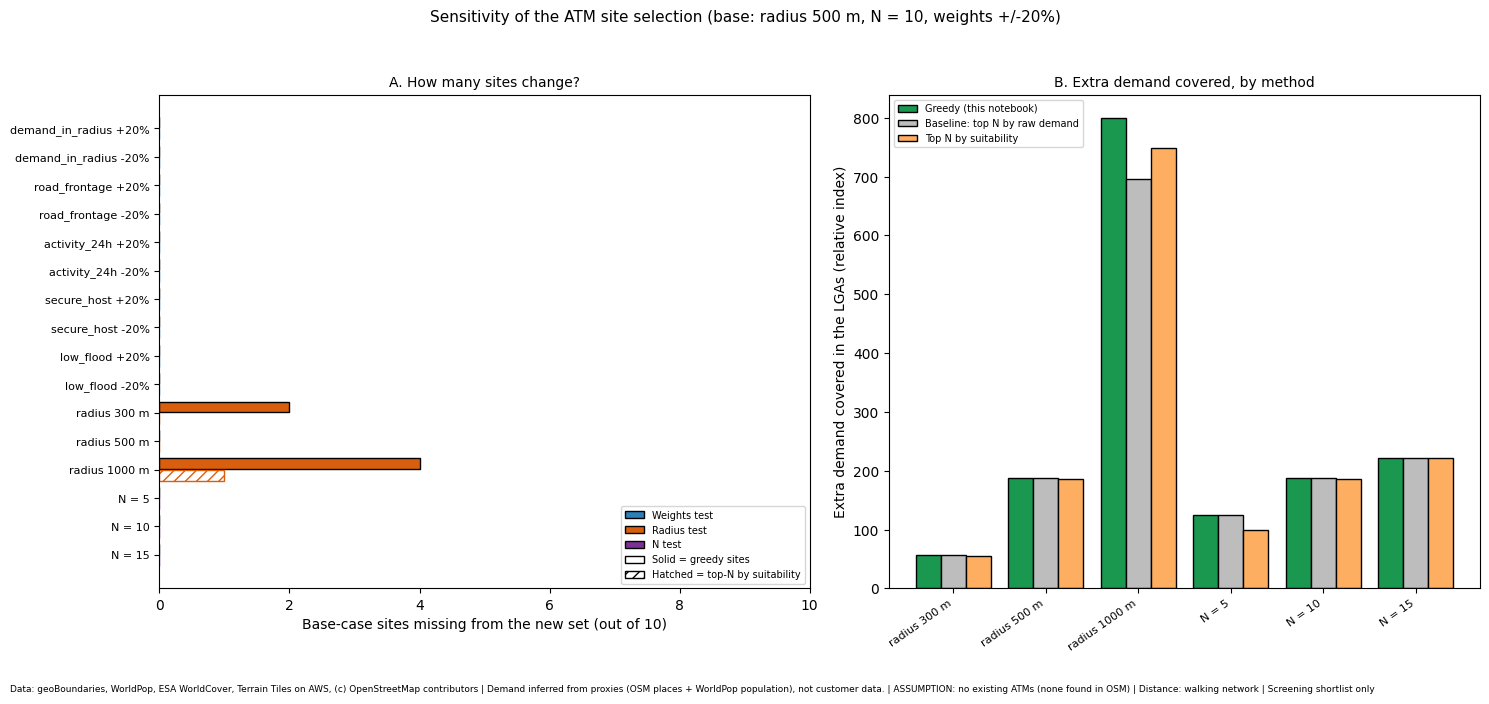

[INFO] Saved: atm_outputs/chart_sensitivity.png
[INFO] Chart check passed.


In [25]:
fig, (axa, axb) = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"width_ratios": [1.1, 1]})

# ---- Left panel: sites changed in each test ----
tests = SENS[SENS["group"] != "base"].reset_index(drop=True)
ypos = np.arange(len(tests))
colors = {"weights": "#2c7fb8", "radius": "#d95f0e", "n_sites": "#7b3294"}
axa.barh(ypos - 0.2, tests["sites_changed"], height=0.38, color=[colors[g] for g in tests["group"]],
         edgecolor="black", label="Greedy sites changed")
axa.barh(ypos + 0.2, tests["top_suit_changed"], height=0.38, color="white",
         edgecolor=[colors[g] for g in tests["group"]], hatch="///", label="Top-N by suitability changed")
axa.set_yticks(ypos)
axa.set_yticklabels(tests["setting"], fontsize=8)
axa.invert_yaxis()                                          # First test at the top.
axa.set_xlabel(f"Base-case sites missing from the new set (out of {len(BASE_G)})")
axa.set_xlim(0, max(len(BASE_G), 1))
axa.set_title("A. How many sites change?", fontsize=10)
axa.legend(handles=[Patch(facecolor="#2c7fb8", edgecolor="black", label="Weights test"),
                    Patch(facecolor="#d95f0e", edgecolor="black", label="Radius test"),
                    Patch(facecolor="#7b3294", edgecolor="black", label="N test"),
                    Patch(facecolor="white", edgecolor="black", label="Solid = greedy sites"),
                    Patch(facecolor="white", edgecolor="black", hatch="///", label="Hatched = top-N by suitability")],
           loc="lower right", fontsize=7)

# ---- Right panel: extra demand covered by each method ----
sub = SENS[SENS["group"].isin(["radius", "n_sites"])].reset_index(drop=True)
xpos = np.arange(len(sub))
wd = 0.27
axb.bar(xpos - wd, sub["greedy_extra_demand"], wd, color="#1a9850", edgecolor="black", label="Greedy (this notebook)")
axb.bar(xpos, sub["demand_base_extra_demand"], wd, color="#bdbdbd", edgecolor="black", label="Baseline: top N by raw demand")
axb.bar(xpos + wd, sub["suit_top_extra_demand"], wd, color="#fdae61", edgecolor="black", label="Top N by suitability")
axb.set_xticks(xpos)
axb.set_xticklabels(sub["setting"], rotation=35, ha="right", fontsize=8)
axb.set_ylabel("Extra demand covered in the LGAs (relative index)")
axb.set_title("B. Extra demand covered, by method", fontsize=10)
axb.legend(fontsize=7, loc="upper left")

_method = "walking network" if DIST_STATE["method"] == "network" else "straight-line (fallback)"
fig.suptitle(f"Sensitivity of the ATM site selection (base: radius {SERVICE_RADIUS_M} m, N = {N_NEW_ATMS}, "
             f"weights +/-{WEIGHT_PERTURB * 100:.0f}%)", fontsize=11)
fig.tight_layout(rect=(0, 0.04, 1, 0.95))
fig.text(0.01, 0.005, f"{CREDITS} | {DEMAND_NOTE} | Distance: {_method} | Screening shortlist only", fontsize=6.5)
MAP_SENS = os.path.join(OUT_DIR, "chart_sensitivity.png")
fig.savefig(MAP_SENS, dpi=OUT_DPI, bbox_inches="tight")
plt.show()
say(f"Saved: {MAP_SENS}")

# ---- Self-tests ----
assert os.path.exists(MAP_SENS), "Sensitivity chart was not saved."
assert len(tests) == len(SENS) - 1, "A test is missing from the chart."
say("Chart check passed.")

In [26]:
GPKG_PATH = os.path.join(OUT_DIR, "atm_sites.gpkg")
ORIGIN = "real data run"                                    # Written into every layer.

def gpkg_layers(path):
    """List the layer names in a GeoPackage. Falls back to fiona in older geopandas."""
    try:
        return list(gpd.list_layers(path)["name"])
    except AttributeError:
        import fiona
        return fiona.listlayers(path)

# ---- Build the three layers (metric) ----
_step = dict(zip(CHOSEN["cand_id"], CHOSEN["step"]))        # Greedy order of each chosen site.
_cand = SC.copy()
_cand["is_chosen"] = _cand["cand_id"].isin(_step)           # True for the final sites.
_cand["greedy_step"] = _cand["cand_id"].map(_step)          # Empty for sites that were not chosen.
_chosen = CHOSEN.merge(STAB[["cand_id", "times_chosen", "tests", "share_pct", "stability"]], on="cand_id", how="left")
_chosen = gpd.GeoDataFrame(_chosen, geometry="geometry", crs=CRS_METRIC)
LAYERS_M = {"candidates": _cand, "chosen_sites": _chosen}
if len(ATMS) > 0:
    LAYERS_M["existing_atms"] = ATMS.copy()                 # An empty layer is skipped.
for _g in LAYERS_M.values():
    _g["data_origin"] = ORIGIN

# ---- Write the six layers ----
if os.path.exists(GPKG_PATH):
    os.remove(GPKG_PATH)                                    # Start clean.
_all = {}
for name, g in LAYERS_M.items():
    _all[f"{name}_utm32632"] = g                            # Metres.
    _all[f"{name}_wgs84"] = g.to_crs(CRS_LATLON)            # Degrees.
for i, (name, g) in enumerate(_all.items()):
    g.to_file(GPKG_PATH, layer=name, driver="GPKG", mode="w" if i == 0 else "a")   # First write creates the file.

# ---- Read it back and print ----
found = gpkg_layers(GPKG_PATH)
print("\nGEOPACKAGE LAYERS")
for name, g in _all.items():
    back = gpd.read_file(GPKG_PATH, layer=name)
    print(f"  {name:<28} {len(back):>5} rows | EPSG:{back.crs.to_epsg()}")
say(f"Saved: {GPKG_PATH} ({os.path.getsize(GPKG_PATH) / 1024:.0f} KB)")

# ---- Self-tests ----
assert set(_all) <= set(found), f"Some layers are missing from the file. Found: {found}"
for name, g in _all.items():
    back = gpd.read_file(GPKG_PATH, layer=name)
    assert len(back) == len(g), f"Row count changed in layer {name}."
    want = 4326 if name.endswith("wgs84") else 32632
    assert back.crs.to_epsg() == want, f"Wrong CRS in layer {name}."
assert len(_all["chosen_sites_wgs84"]) == len(CHOSEN), "Chosen-site count is wrong in the file."
assert int(_cand["is_chosen"].sum()) == len(CHOSEN), "is_chosen does not match the chosen sites."
_b = gpd.read_file(GPKG_PATH, layer="chosen_sites_wgs84").total_bounds
assert -180 <= _b[0] <= _b[2] <= 180 and -90 <= _b[1] <= _b[3] <= 90, "Degrees look wrong."
say("Self-tests passed: six layers, right row counts, right CRS, chosen sites flagged.")


GEOPACKAGE LAYERS
  candidates_utm32632             15 rows | EPSG:32632
  candidates_wgs84                15 rows | EPSG:4326
  chosen_sites_utm32632           10 rows | EPSG:32632
  chosen_sites_wgs84              10 rows | EPSG:4326
[INFO] Saved: atm_outputs/atm_sites.gpkg (176 KB)
[INFO] Self-tests passed: six layers, right row counts, right CRS, chosen sites flagged.


In [27]:
import datetime

BRIEF_MD = os.path.join(OUT_DIR, "decision_brief.md")
CHECKLIST_MD = os.path.join(OUT_DIR, "field_checklist.md")

def fnum(v, spec):
    """Format a number, or say 'not available' if it is missing."""
    return "not available" if (v is None or pd.isna(v)) else format(v, spec)

_method = "walking network" if DIST_STATE["method"] == "network" else "straight-line (fallback)"
_banner = ("> **ASSUMPTION: no existing ATMs.** OSM returned no ATMs for this area, so this analysis assumes there are none. "
           "All demand counts as uncovered, 'coverage before' is 0% by assumption, and sites are not spaced from any "
           "existing ATM. ATMs may exist that OSM does not show: check each site for nearby ATMs before using these results.\n\n"
           if NO_ATM_ASSUMED else "")

# ---- Pull the real numbers ----
LROW = COV_TABLE[COV_TABLE["scope"].str.startswith("LGAs")].iloc[0]
n_sites = int(LROW["n_new_sites"])
before, after = LROW["demand_covered_before_pct"], LROW["demand_covered_after_pct"]
extra_pop = LROW["extra_population_covered"]
gap_before, gap_after = LROW["gap_area_before_km2"], LROW["gap_area_after_km2"]

_wt = SENS[SENS["group"] == "weights"]
_rd = SENS[(SENS["group"] == "radius") & (SENS["radius_m"] != SERVICE_RADIUS_M)]
_rd_txt = "; ".join(f"{int(r.radius_m)} m: {int(r.sites_changed)} of {len(BASE_G)} changed"
                    for r in _rd.itertuples()) or "no other radius was tested"
_n_sens = int((STAB["stability"] == "sensitive").sum())
_n_stable = int((STAB["stability"] == "stable").sum())
_b = SENS.iloc[0]
_vs = _b["greedy_vs_demand_baseline_pct"]
_demand_src = ("customer data (anonymised CSV) plus proxies" if DEM["shares"].get("customers") else
               "proxies (OSM places and WorldPop population), not customer data")

# ---- The decision brief ----
brief = [f"# Decision brief: new bank ATM sites, Calabar Municipal and Calabar South",
         f"**SCREENING SHORTLIST, NOT A FINAL APPROVAL.** Generated {datetime.date.today().isoformat()}.", "",
         _banner.strip(), "",
         f"Settings: service radius {SERVICE_RADIUS_M} m, {n_sites} new sites asked for N = {N_NEW_ATMS}, "
         f"minimum spacing {MIN_SPACING_M} m, distance method: {_method}. Demand is from {_demand_src}.", "",
         "## Key finding",
         f"Adding the {n_sites} sites below would raise the share of demand within {SERVICE_RADIUS_M} m of an ATM, "
         f"inside the two LGAs, from {fnum(before, '.1f')}% to {fnum(after, '.1f')}%. "
         f"Demand is a relative index, not a count of customers or money. This is a modelled result that needs field checks.", "",
         "## Three numbers (inside the two LGAs)",
         f"1. **Demand covered:** {fnum(before, '.1f')}% before, {fnum(after, '.1f')}% after.",
         f"2. **Extra people covered:** {fnum(extra_pop, ',.0f')} (WorldPop 2020 estimate, modelled).",
         f"3. **Sites and remaining gap:** {n_sites} sites. Uncovered area falls from {fnum(gap_before, '.2f')} km2 "
         f"to {fnum(gap_after, '.2f')} km2.", "",
         "## Three limits",
         "1. **Data:** OpenStreetMap is incomplete. Population is a 2020 estimate. Demand is inferred from proxies "
         "unless customer data were supplied, so it is a relative index.",
         f"2. **Modelling and placeholders:** distances are modelled ({_method}). The flood rule (elevation of at least "
         f"{LOW_ELEV_M:g} m), the AHP matrix, the score scales and the 24-hour activity and security proxies are my "
         "placeholder judgements. They have not been checked against local knowledge.",
         f"3. **Method:** the greedy step picks by coverage gain, and suitability only breaks ties or applies the "
         f"MIN_SUITABILITY floor ({MIN_SUITABILITY:g}). Weight tests changed at least one greedy site in "
         f"{int((_wt['sites_changed'] > 0).sum())} of {len(_wt)} runs. Radius tests: {_rd_txt}. "
         f"{_n_stable} sites were stable and {_n_sens} were sensitive. Greedy covered {fnum(_vs, '+.1f')}% "
         f"new demand compared with the raw-demand baseline.", "",
         "## Three recommendations",
         "1. **Verify every site in the field** with `field_checklist.md`. Start with the sites marked sensitive, "
         "unnamed, or with unknown elevation.",
         "2. **Replace placeholders and validate.** Use a local flood layer or threshold, have the team review the AHP "
         "matrix, and compare the demand surface with the bank's own anonymised transaction or customer data.",
         "3. **Check the rules before any deployment.** Read the Central Bank of Nigeria's current guidance, the bank's "
         "policy, and (if customer data are used) the Nigeria Data Protection Act. Treat this list as a shortlist.", "",
         "## Chosen sites (greedy order)",
         "| Step | ID | Name | Host | Lat | Lon | Extra people | Stability |", "|---|---|---|---|---|---|---|---|"]
_stab = STAB.set_index("cand_id")
for r in CHOSEN.itertuples():
    brief.append(f"| {int(r.step)} | {r.cand_id} | {r.name} | {r.host_type} | {r.lat:.5f} | {r.lon:.5f} | "
                 f"{fnum(r.gain_pop if HAS_POP else np.nan, ',.0f')} | {_stab.loc[r.cand_id, 'stability']} |")
BRIEF_TEXT = "\n".join(brief) + "\n"
with open(BRIEF_MD, "w", encoding="utf-8") as f:
    f.write(BRIEF_TEXT)

# ---- The field checklist ----
CHECK_ITEMS = [
    "Visibility: can people see the spot from the road and from the host entrance? Is anything blocking the view?",
    "Lighting: is the spot well lit at night? Visit after dark.",
    "Security: guard, CCTV, staff on site? Is the spot exposed to the street?",
    "Power: is mains power reliable? Is there a generator or backup, and space for the machine?",
    "Flood marks: water lines on walls, standing water, blocked drains. Ask neighbours about past floods.",
    "Lease permission: who owns the site, and will they agree in writing?",
    "Customer access at night: can customers reach it safely, on foot, after dark? Is the site open?",
    "Exact placement: the OSM point is the centre of the place. Mark the real door or spot.",
    "Missing ATMs: is there an ATM nearby that OSM does not show?"]
_scx = SC.set_index("cand_id")

def flags(cid):
    """Desk-check warnings for one chosen site, drawn from the data."""
    r, out = _scx.loc[cid], []
    if r["host_type"] == "universities":
        out.append("University: the point is the campus centre, not a gate. Find the real gate.")
    if r["name"] == "(unnamed)":
        out.append("Unnamed in OSM: confirm what the place is.")
    if "low_flood" in KEPT and bool(r["elev_unknown"]):
        out.append("Elevation unknown: the flood rule could not be applied here.")
    if "road_class" in _scx.columns and pd.isna(r["road_class"]):
        out.append(f"No mapped road within {FRONTAGE_SEARCH_M} m: check the access road.")
    if _stab.loc[cid, "stability"] == "sensitive":
        out.append("Sensitive in the weight or radius tests: it depends on the assumptions.")
    return out

chk = ["# Field verification checklist", _banner.strip(),
       "Screening shortlist only. Fill one section per site, on site, by day and after dark. "
       "Coordinates are OSM place centres and may be a few metres off.", ""]
for r in CHOSEN.itertuples():
    chk += [f"## Site {int(r.step)}: {r.cand_id} - {r.name}",
            f"- Host type: {r.host_type} | Lat, Lon: {r.lat:.5f}, {r.lon:.5f} | Suitability: {r.suitability:.1f} "
            f"(rank {int(r.suitability_rank)})",
            f"- Why chosen: {r.reason}"]
    for fl in flags(r.cand_id):
        chk.append(f"- **Flag:** {fl}")
    chk += [f"- [ ] {item}" for item in CHECK_ITEMS]
    chk += ["- Notes: ", "- Decision: keep / move / reject (circle one) | Checked by: ________ | Date: ________", ""]
CHECK_TEXT = "\n".join(chk) + "\n"
with open(CHECKLIST_MD, "w", encoding="utf-8") as f:
    f.write(CHECK_TEXT)

# ---- Print ----
print(BRIEF_TEXT)
print("---- First site of the field checklist ----")
print("## Site " + CHECK_TEXT.split("\n## Site ")[1] if len(CHOSEN) else "")
say(f"Saved: {BRIEF_MD} and {CHECKLIST_MD}")

# ---- Self-tests ----
assert f"{fnum(before, '.1f')}% to {fnum(after, '.1f')}%" in BRIEF_TEXT, "Brief numbers do not match COV_TABLE."
assert after >= before - 1e-9, "Coverage after is below coverage before."
assert BRIEF_TEXT.count("\n1. ") >= 3 and BRIEF_TEXT.count("\n3. ") >= 3, "Brief is missing numbered items."
assert all(h in BRIEF_TEXT for h in ("## Key finding", "## Three numbers", "## Three limits", "## Three recommendations")), "A brief section is missing."
assert CHECK_TEXT.count("\n## Site ") == len(CHOSEN), "Checklist needs one section per chosen site."
assert CHECK_TEXT.count("- [ ] ") == len(CHOSEN) * len(CHECK_ITEMS), "A checklist item is missing."
assert all(cid in CHECK_TEXT for cid in CHOSEN["cand_id"]), "A chosen site is missing from the checklist."
say("Self-tests passed: brief numbers match the coverage table, one checklist section per site.")

# Decision brief: new bank ATM sites, Calabar Municipal and Calabar South
**SCREENING SHORTLIST, NOT A FINAL APPROVAL.** Generated 2026-11-09.

> **ASSUMPTION: no existing ATMs.** OSM returned no ATMs for this area, so this analysis assumes there are none. All demand counts as uncovered, 'coverage before' is 0% by assumption, and sites are not spaced from any existing ATM. ATMs may exist that OSM does not show: check each site for nearby ATMs before using these results.

Settings: service radius 500 m, 10 new sites asked for N = 10, minimum spacing 150 m, distance method: walking network. Demand is from proxies (OSM places and WorldPop population), not customer data.

## Key finding
Adding the 10 sites below would raise the share of demand within 500 m of an ATM, inside the two LGAs, from 0.0% to 11.9%. Demand is a relative index, not a count of customers or money. This is a modelled result that needs field checks.

## Three numbers (inside the two LGAs)
1. **Demand covered:** 0.0% bef

In [28]:
import zipfile

# ---- Check that every expected output exists ----
EXPECTED = {"maps and chart": [MAP_DEMAND, MAP_GAPS, MAP_CAND, MAP_SUIT, MAP_FINAL, MAP_SENS],
            "tables": [WEIGHTS_CSV, TOP15_CSV, SCORES_CSV, FUNNEL_CSV, GAP_CSV, SELECTED_CSV, COVERAGE_CSV, SENS_CSV, STAB_CSV],
            "spatial": [GPKG_PATH],
            "documents": [BRIEF_MD, CHECKLIST_MD]}
_missing = [p for group in EXPECTED.values() for p in group if not os.path.exists(p)]
if _missing:
    raise FileNotFoundError(f"Missing outputs: {_missing}. Run the cells that make them, then run this cell again.")

# ---- Make the zip (outside the output folder) ----
ZIP_PATH = f"{OUT_DIR}.zip"
if os.path.exists(ZIP_PATH):
    os.remove(ZIP_PATH)
with zipfile.ZipFile(ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED) as z:
    for root, _, names in os.walk(OUT_DIR):
        for nm in sorted(names):
            full = os.path.join(root, nm)
            z.write(full, arcname=os.path.relpath(full, OUT_DIR))   # Paths inside the zip start at the output folder.

# ---- Print what is inside ----
print("\nZIP CONTENTS")
with zipfile.ZipFile(ZIP_PATH) as z:
    inside = z.namelist()
    for info in z.infolist():
        print(f"  {info.filename:<34} {info.file_size / 1024:8.1f} KB")
say(f"Zip: {os.path.abspath(ZIP_PATH)} ({os.path.getsize(ZIP_PATH) / 1024:.0f} KB, {len(inside)} files)")

# ---- Try to download ----
warn("Colab files are DELETED when the session ends. Download the zip now.")
try:
    from google.colab import files
    files.download(ZIP_PATH)
    say("Download started. If nothing happens, allow pop-ups, or use the Files panel (folder icon, left side).")
except ImportError:
    warn("Not running in Colab, so no download was started. Take the zip from your working folder.")
except Exception as e:
    warn(f"Download did not start ({type(e).__name__}: {str(e)[:100]}). Use the Files panel to download the zip by hand.")

# ---- Self-tests ----
_expected_names = {os.path.basename(p) for g in EXPECTED.values() for p in g}
assert _expected_names <= {os.path.basename(n) for n in inside}, "The zip is missing an expected file."
assert not any(n.endswith(".zip") for n in inside), "A zip was zipped inside the zip."
assert os.path.getsize(ZIP_PATH) > 0, "The zip is empty."
say("Self-tests passed: every expected output is in the zip.")

# ---- Final reminders ----
print("\nREMINDERS")
print(" 1. This is a SCREENING SHORTLIST, not a final approval. Every site needs a field check.")
print(" 2. OSM is incomplete, population is a 2020 estimate, demand is inferred from proxies, distances are modelled.")
print(" 3. Check the Central Bank of Nigeria's CURRENT guidance and the bank's own policy before any deployment.")
if CUSTOMER_CSV:
    print(" 4. Customer data: use anonymised or aggregated data only, and follow the Nigeria Data Protection Act.")


ZIP CONTENTS
  atm_sites.gpkg                        176.0 KB
  candidate_funnel.csv                    0.2 KB
  candidate_scores_all.csv                5.5 KB
  chart_sensitivity.png                 242.6 KB
  coverage_before_after.csv               0.7 KB
  criteria_weights.csv                    0.6 KB
  decision_brief.md                       3.7 KB
  field_checklist.md                     12.2 KB
  gap_summary.csv                         0.4 KB
  map_candidates_filtered.png           225.7 KB
  map_coverage_gaps.png                 263.2 KB
  map_demand_surface.png                226.8 KB
  map_final_sites.png                   303.2 KB
  map_suitability.png                   251.8 KB
  selected_sites.csv                      2.8 KB
  sensitivity_results.csv                 2.8 KB
  site_stability.csv                      0.8 KB
  top15_candidates.csv                    3.7 KB
[INFO] Zip: /content/atm_outputs.zip (1366 KB, 18 files)
[WARNING] Colab files are DELETED when the sess

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

[INFO] Download started. If nothing happens, allow pop-ups, or use the Files panel (folder icon, left side).
[INFO] Self-tests passed: every expected output is in the zip.

REMINDERS
 1. This is a SCREENING SHORTLIST, not a final approval. Every site needs a field check.
 2. OSM is incomplete, population is a 2020 estimate, demand is inferred from proxies, distances are modelled.
 3. Check the Central Bank of Nigeria's CURRENT guidance and the bank's own policy before any deployment.
